# **Prepared by Oh Yu Qiao (24013567)**

# Graded Open-Ended Lab

## Sequential Data Prediction in Engineering Using Autoregressive (AR) Models and Long Short-Term Memory (LSTM) Networks

**Objective**
This lab explores the application of sequential data prediction in engineering contexts evaluating the performance of both traditional Autoregressive (AR) models and modern Long Short-Term Memory (LSTM) neural networks.

The following section shows the code sample to implement an AR model and an LSTM model.

### Code Sample for AR and LSTM models

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

The following code block generate a time series data using the sine function and a normally distributed white noise.

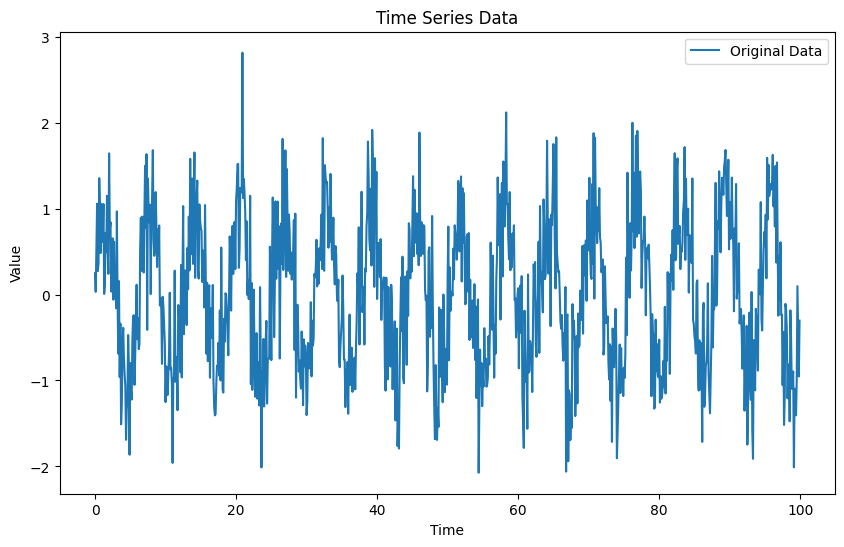

In [2]:
# Example: Creating a sine wave with noise as the time series data
np.random.seed(42)
time = np.arange(0, 100, 0.1)
data_values = np.sin(time) + np.random.normal(scale=0.5, size=len(time))

# Convert to pandas DataFrame
df = pd.DataFrame({'time': time, 'value': data_values})

# Plot the data
plt.figure(figsize=(10,6))
plt.plot(df['time'], df['value'], label='Original Data')
plt.title('Time Series Data')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

# Split the data into train and test sets
train_size = int(len(df) * 0.8)
train_data = df['value'][:train_size]
test_data = df['value'][train_size:]

### Exploratory Visualizations: ACF and PACF for AR Lag Selection
Before fitting an Autoregressive model, plotting the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) helps students analytically determine the optimal lag order instead of guessing.

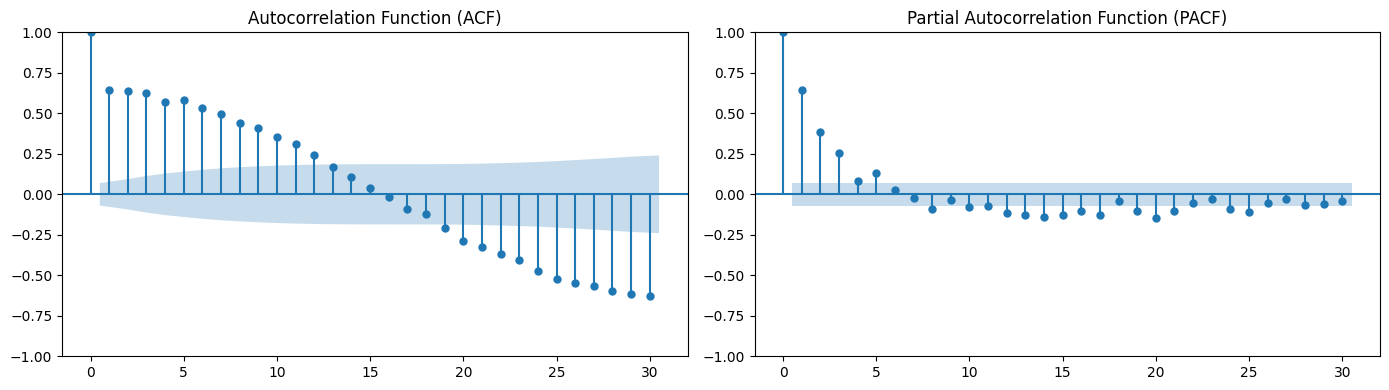

In [3]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(train_data, ax=axes[0], lags=30)
axes[0].set_title('Autocorrelation Function (ACF)')
plot_pacf(train_data, ax=axes[1], lags=30, method='ywm')
axes[1].set_title('Partial Autocorrelation Function (PACF)')
plt.tight_layout()
plt.show()

In [4]:
from statsmodels.tsa.ar_model import AutoReg
from sklearn.metrics import root_mean_squared_error

The following code block shows the training and evaluation of a autoregressive (AR) model with lags of 5.

In [5]:
# Fit the Autoregressive (AR) model
model_ar = AutoReg(train_data, lags=5)  # Using lag=5 as an example
model_fit = model_ar.fit()

# Print summary of the model
print(model_fit.summary())

# Make predictions
predictions_ar = model_fit.predict(start=len(train_data), end=len(df)-1, dynamic=False)

# Evaluate the model
rmse = root_mean_squared_error(test_data, predictions_ar)
print(f'RMSE of the AR Model: {rmse}')

                            AutoReg Model Results                             
Dep. Variable:                  value   No. Observations:                  795
Model:                     AutoReg(5)   Log Likelihood                -673.056
Method:               Conditional MLE   S.D. of innovations              0.564
Date:                Tue, 24 Nov 2026   AIC                           1360.111
Time:                        02:12:34   BIC                           1392.859
Sample:                             5   HQIC                          1372.695
                                  800                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0027      0.020     -0.135      0.893      -0.042       0.037
value.L1       0.2626      0.035      7.470      0.000       0.194       0.332
value.L2       0.2342      0.036      6.453      0.0

In [6]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.metrics import mean_squared_error

The following code block shows the data preprocessing prior to LSTM model training specifically:
1. min-max scaling
2. converting the sequential data into chunks of 10
3. splitting the data into training and testing data with 80:20 ratio
4. reshaping the training and testing data to be compatible with LSTM

In [7]:
# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df['value'].values.reshape(-1,1))

# Create sequences for LSTM
def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

sequence_length = 10
X, y = create_sequences(scaled_data, sequence_length)

# Split the data into training and testing sets
train_size_lstm = int(len(X) * 0.8)
X_train, X_test = X[:train_size_lstm], X[train_size_lstm:]
y_train, y_test = y[:train_size_lstm], y[train_size_lstm:]

# Reshape the data to be compatible with LSTM (samples, time steps, features)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

The following code block shows the construction and training of an LSTM network with 50 units of hidden neurons.

In [8]:
# Build the LSTM model
model = Sequential()
model.add(LSTM(50, input_shape=(X_train.shape[1], 1)))
model.add(Dense(1))  # Output layer
model.compile(optimizer='adam', loss='mse')

# Train the LSTM model
history = model.fit(X_train, y_train, epochs=30, batch_size=32, validation_data=(X_test, y_test), verbose=0)

# Make predictions
predicted_test = model.predict(X_test)
predicted_test = scaler.inverse_transform(predicted_test)
y_test_rescaled = scaler.inverse_transform(y_test.reshape(-1, 1))

# Evaluate the model
rmse_lstm = root_mean_squared_error(y_test_rescaled, predicted_test)
print(f'RMSE of the LSTM Model: {rmse_lstm}')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
RMSE of the LSTM Model: 0.5527473736740174


### Advanced Comparative Visualizations
To better evaluate micro-level tracking, phase lags, and error distribution between AR and LSTM models, run the visualization cells below.

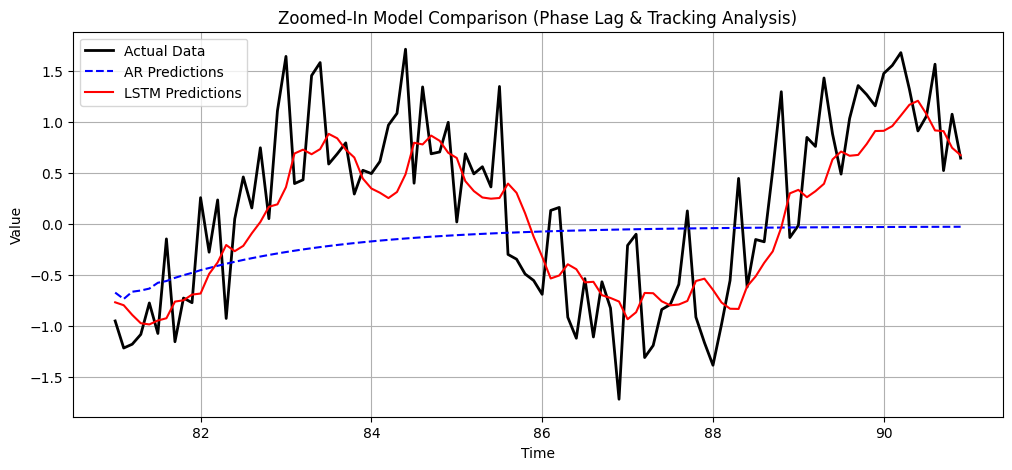

In [9]:
# 1. Zoomed-In Comparison Window (First 100 test steps)
zoom_steps = 100
test_time_axis = df['time'][train_size + sequence_length : train_size + sequence_length + zoom_steps]

plt.figure(figsize=(12, 5))
plt.plot(test_time_axis, y_test_rescaled[:zoom_steps], label='Actual Data', color='black', linewidth=2)
plt.plot(test_time_axis, predictions_ar.iloc[:zoom_steps], label='AR Predictions', color='blue', linestyle='--')
plt.plot(test_time_axis, predicted_test[:zoom_steps], label='LSTM Predictions', color='red')
plt.title('Zoomed-In Model Comparison (Phase Lag & Tracking Analysis)')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.show()

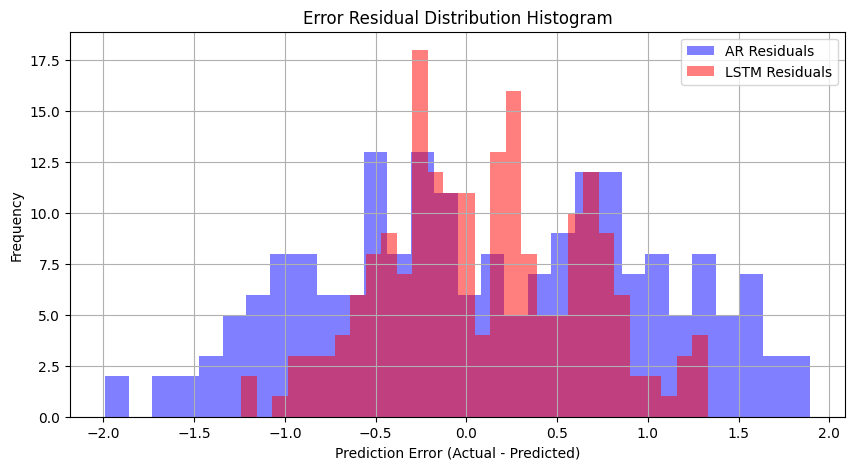

In [10]:
# 2. Residual Error Distribution
ar_residuals = test_data.values[:len(predicted_test)] - predictions_ar.values[:len(predicted_test)]
lstm_residuals = y_test_rescaled.flatten() - predicted_test.flatten()

plt.figure(figsize=(10, 5))
plt.hist(ar_residuals, bins=30, alpha=0.5, label='AR Residuals', color='blue')
plt.hist(lstm_residuals, bins=30, alpha=0.5, label='LSTM Residuals', color='red')
plt.title('Error Residual Distribution Histogram')
plt.xlabel('Prediction Error (Actual - Predicted)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.show()

## Instructions

Download the training and testing data by running the following code block. You can view the downloaded files by clicking on "Files" on the vertical toolbar on the left side of this Jupyter notebook.

The original dataset is provided by https://www.kaggle.com/datasets/sumanthvrao/daily-climate-time-series-data.

In [11]:
!gdown 17kLwUsh0N_bBwmbrvcbOC8L_8I49CyvX
!gdown 18jUJjBe3y3hHxexZfTWORaePrxu7qsAM

Downloading...
From: https://drive.google.com/uc?id=17kLwUsh0N_bBwmbrvcbOC8L_8I49CyvX
To: /content/DailyDelhiClimateTrain.csv
100% 78.2k/78.2k [00:00<00:00, 93.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=18jUJjBe3y3hHxexZfTWORaePrxu7qsAM
To: /content/DailyDelhiClimateTest.csv
100% 7.10k/7.10k [00:00<00:00, 27.6MB/s]


In [12]:
!ls -lh *.csv

-rw-r--r-- 1 root root 7.0K Oct 16  2024 DailyDelhiClimateTest.csv
-rw-r--r-- 1 root root  77K Oct 16  2024 DailyDelhiClimateTrain.csv


---
# Lab Report: AR vs LSTM for Daily Temperature Prediction
**Name:** Oh Yu Qiao | **Student ID:** 24013567

## Abstract
This report compares an autoregressive (AR) model and a Long Short-Term Memory (LSTM)
network for one-day-ahead forecasting of daily mean temperature in Delhi (2013–2017).
Exploratory analysis (ADF test, ACF/PACF, seasonal decomposition) guided lag and window
selection, and both models were tuned on a chronological validation set using controlled,
multi-seed experiments. On the held-out 2017 test set, AR(11) achieved an RMSE of
1.700 °C and the LSTM 1.707–1.878 °C depending on the retraining protocol, while a naive
persistence forecast achieved 1.684 °C. Diagnostic analysis showed a one-day phase lag
and amplitude dampening in both models, and almost identical error patterns (residual
correlation 0.971). The results indicate that, for this short-horizon and linearly
dominated problem, the simpler AR model offers equivalent accuracy at a small fraction of
the computational cost.

## 1. Setup

In [13]:
# Libraries Imports
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.ar_model import AutoReg, ar_select_order
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (root_mean_squared_error,
                             mean_absolute_error,
                             mean_absolute_percentage_error)

# Reproducibility: fix all random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Plot style
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True
tf.get_logger().setLevel('ERROR')

All the libraries required are imported in one place. Furthermore, the random seeds for Python, NumPy and TensorFlow are also fixed with the value of 42, so that the results, especially LSTM training are reproducible when we rerun the notebook.

## 2. Data Loading and Cleaning
The dataset used is the Daily Delhi Climate dataset from Kaggle. Each row is one day with four variables: mean temperature (°C), humidity (%), wind speed (km/h) and mean pressure (hPa). The target variable for this study is **meantemp** (daily mean temperature).

In [14]:
# Load train and test files
train_df = pd.read_csv('DailyDelhiClimateTrain.csv', parse_dates=['date'], index_col='date')
test_df  = pd.read_csv('DailyDelhiClimateTest.csv',  parse_dates=['date'], index_col='date')

train_df = train_df.sort_index()
test_df  = test_df.sort_index()

# Display information regarding the data
print(f"Train: {train_df.shape[0]} rows, {train_df.index.min().date()} to {train_df.index.max().date()}")
print(f"Test : {test_df.shape[0]} rows, {test_df.index.min().date()} to {test_df.index.max().date()}")
display(train_df.head())

Train: 1462 rows, 2013-01-01 to 2017-01-01
Test : 114 rows, 2017-01-01 to 2017-04-24


,meantemp,humidity,wind_speed,meanpressure
date,,,,
2013-01-01,10.000000,84.500000,0.000000,1015.666667
2013-01-02,7.400000,92.000000,2.980000,1017.800000
2013-01-03,7.166667,87.000000,4.633333,1018.666667
2013-01-04,8.666667,71.333333,1.233333,1017.166667
2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [15]:
# Checking for Inconsistency, gaps, missing data in the database

# 1. Missing values
print("Missing values (train):\n", train_df.isna().sum(), "\n")
print("Missing values (test):\n",  test_df.isna().sum(), "\n")

# 2. Duplicate dates
print("Duplicate dates in train:", train_df.index.duplicated().sum())
print("Duplicate dates in test :", test_df.index.duplicated().sum())

# 3. Overlap between train and test
overlap = train_df.index.intersection(test_df.index)
print("Dates appearing in BOTH train and test:", list(overlap.date))

# 4. Gaps: is every day present?
for name, d in [('train', train_df), ('test', test_df)]:
    full_range = pd.date_range(d.index.min(), d.index.max(), freq='D')
    print(f"Missing days in {name}: {len(full_range.difference(d.index))}")

# 5. Summary statistics (look for impossible values)
display(train_df.describe().round(2))
display(test_df.describe().round(2))

Missing values (train):
 meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64 

Missing values (test):
 meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64 

Duplicate dates in train: 0
Duplicate dates in test : 0
Dates appearing in BOTH train and test: [datetime.date(2017, 1, 1)]
Missing days in train: 0
Missing days in test: 0


,meantemp,humidity,wind_speed,meanpressure
count,1462.00,1462.00,1462.00,1462.00
mean,25.50,60.77,6.80,1011.10
std,7.35,16.77,4.56,180.23
min,6.00,13.43,0.00,-3.04
25%,18.86,50.38,3.48,1001.58
50%,27.71,62.62,6.22,1008.56
75%,31.31,72.22,9.24,1014.94
max,38.71,100.00,42.22,7679.33


,meantemp,humidity,wind_speed,meanpressure
count,114.00,114.00,114.00,114.00
mean,21.71,56.26,8.14,1004.04
std,6.36,19.07,3.59,89.47
min,11.00,17.75,1.39,59.00
25%,16.44,39.62,5.56,1007.44
50%,19.88,57.75,8.07,1012.74
75%,27.71,71.90,10.07,1016.74
max,34.50,95.83,19.31,1022.81


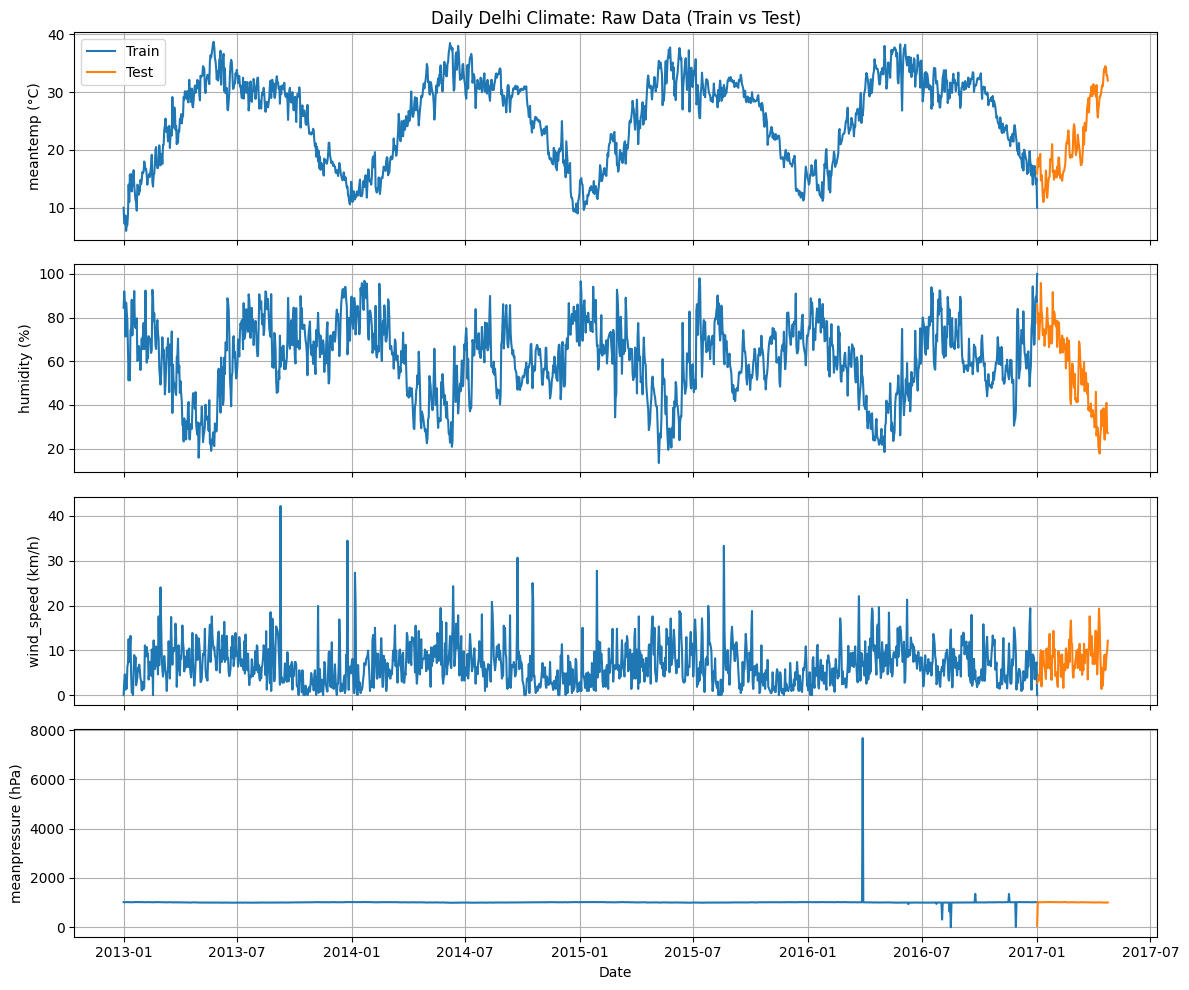

In [16]:
# Quick visual check for all four variables to make sure that they are consistent and the split is good
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, col, unit in zip(axes,
                         ['meantemp', 'humidity', 'wind_speed', 'meanpressure'],
                         ['°C', '%', 'km/h', 'hPa']):
    ax.plot(train_df.index, train_df[col], label='Train', color='tab:blue')
    ax.plot(test_df.index,  test_df[col],  label='Test',  color='tab:orange')
    ax.set_ylabel(f'{col} ({unit})')
axes[0].legend()
axes[0].set_title('Daily Delhi Climate: Raw Data (Train vs Test)')
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

### Data quality findings

**Table 1. Summary of data quality checks**

| Check | Finding | Action taken |
|---|---|---|
| Missing values | None in either file **(ok)** | None required |
| Missing days | None; both files are continuous daily series **(ok)** | None required |
| Train/test overlap | 2017-01-01 appears in both files **(not ok)** | Removed from the training set |
| Final training row (2017-01-01) | Abrupt drop in mean temperature to 10 °C and humidity of 100%, inconsistent with surrounding days **(not ok)** | Resolved by the removal above (same row) |
| `meanpressure` range | Train: min −3.04 hPa, max 7679 hPa. Test: min 59 hPa. Realistic range ≈ 950–1050 hPa **(not ok)** | Out-of-range values (9 train, 1 test) replaced by time-based linear interpolation |
| `meantemp` range | Train: 6.0–38.7 °C. Test: 11.0–34.5 °C **(ok)** | None required; test values lie within the training range |

In [17]:
## Cleaning the database

# 1. Remove the overlapping date from the training set
# 2017-01-01 appears in both files. The training-file version is anomalous
# (sudden temperature drop, humidity = 100%), and keeping it would also let
# the test period leak into training. The test-file version is kept.
print("Training row being removed:\n", train_df.loc['2017-01-01'], "\n")
train_df = train_df.drop(pd.Timestamp('2017-01-01'))

# 2. Clean physically impossible meanpressure values
# Realistic sea-level pressure is roughly 950-1050 hPa. Values outside this
# range are sensor errors: replace them with NaN, then fill them by
# time-based linear interpolation from neighbouring days.
P_MIN, P_MAX = 950, 1050

def clean_pressure(d, name):
    d = d.copy()
    bad = (d['meanpressure'] < P_MIN) | (d['meanpressure'] > P_MAX)
    print(f"{name}: {bad.sum()} invalid meanpressure values replaced")
    d.loc[bad, 'meanpressure'] = np.nan
    d['meanpressure'] = d['meanpressure'].interpolate(method='time').bfill().ffill()
    return d

train_df = clean_pressure(train_df, 'Train')
test_df  = clean_pressure(test_df,  'Test')

# 3. Confirm the result
print(f"\nTrain: {len(train_df)} rows, {train_df.index.min().date()} to {train_df.index.max().date()}")
print(f"Test : {len(test_df)} rows, {test_df.index.min().date()} to {test_df.index.max().date()}")
display(train_df.describe().round(2))

Training row being removed:
 meantemp          10.0
humidity         100.0
wind_speed         0.0
meanpressure    1016.0
Name: 2017-01-01 00:00:00, dtype: float64 

Train: 9 invalid meanpressure values replaced
Test: 1 invalid meanpressure values replaced

Train: 1461 rows, 2013-01-01 to 2016-12-31
Test : 114 rows, 2017-01-01 to 2017-04-24


,meantemp,humidity,wind_speed,meanpressure
count,1461.00,1461.00,1461.00,1461.00
mean,25.51,60.74,6.81,1008.24
std,7.34,16.74,4.56,7.44
min,6.00,13.43,0.00,991.38
25%,18.86,50.38,3.48,1001.62
50%,27.71,62.62,6.25,1008.56
75%,31.31,72.12,9.25,1014.88
max,38.71,98.00,42.22,1023.00


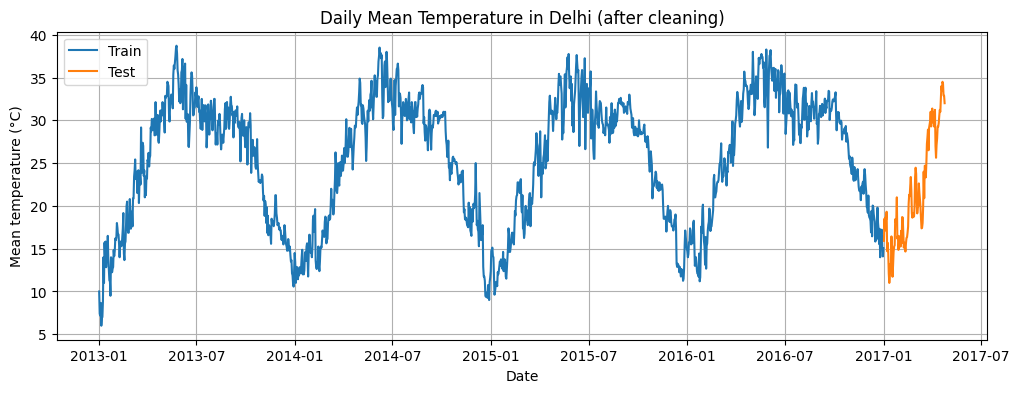

In [18]:
# Revised visual check after cleaning
plt.figure(figsize=(12, 4))
plt.plot(train_df.index, train_df['meantemp'], label='Train', color='tab:blue')
plt.plot(test_df.index,  test_df['meantemp'],  label='Test',  color='tab:orange')
plt.title('Daily Mean Temperature in Delhi (after cleaning)')
plt.xlabel('Date')
plt.ylabel('Mean temperature (°C)')
plt.legend()
plt.show()

### Cleaning decisions


**Discussion of cleaning decisions**

- **Train/test overlap:** The training-file entry for 2017-01-01 was removed so the test set remains completely unseen during training, and because its values are anomalous compared with neighbouring days. Final dataset sizes are **1461 training days** (2013-01-01 to 2016-12-31) and **114 test days** (2017-01-01 to 2017-04-24).
- **Pressure sensor errors:** Values outside 950–1050 hPa are physically impossible at Delhi's elevation and were treated as sensor faults. 9 training and 1 test values were replaced by interpolation. This does not affect the univariate models, which use only `meantemp`, but it makes the data valid for any multivariate extension.
- **Target range and scaling:** Because test temperatures fall within the training range, a MinMax scaler fitted on the training data alone maps the test data into [0, 1] without extrapolation.
- **Seasonality:** `meantemp` shows a strong yearly cycle (cold in Dec–Jan, hot in May–Jun). The test period (Jan–Apr 2017) covers the **warming phase** of this cycle, so the models are evaluated on a rising trend.

## 3. Exploratory Data Analysis (EDA)
All exploratory analysis is performed on the **training data only**, so that no information from the test period influences modelling decisions such as lag selection.

In [19]:
# Testing whether it is stationary using ADF
def adf_report(series, name):
    """Run the Augmented Dickey-Fuller test and return the key results as a dict."""
    stat, pvalue, usedlag, nobs, crit, _ = adfuller(series.dropna(), autolag='AIC', result_object=False)
    return {
        'Series': name,
        'ADF statistic': round(stat, 3),
        'p-value': round(pvalue, 4),
        'Critical value (5%)': round(crit['5%'], 3),
        'Stationary at 5%?': 'Yes' if pvalue < 0.05 else 'No',
    }

y_train = train_df['meantemp']

adf_table = pd.DataFrame([
    adf_report(y_train, 'meantemp (original)'),
    adf_report(y_train.diff(), 'meantemp (first difference)'),
])
display(adf_table)

,Series,ADF statistic,p-value,Critical value (5%),Stationary at 5%?
0,meantemp (original),-2.156,0.2228,-2.864,No
1,meantemp (first difference),-16.520,0.0000,-2.864,Yes


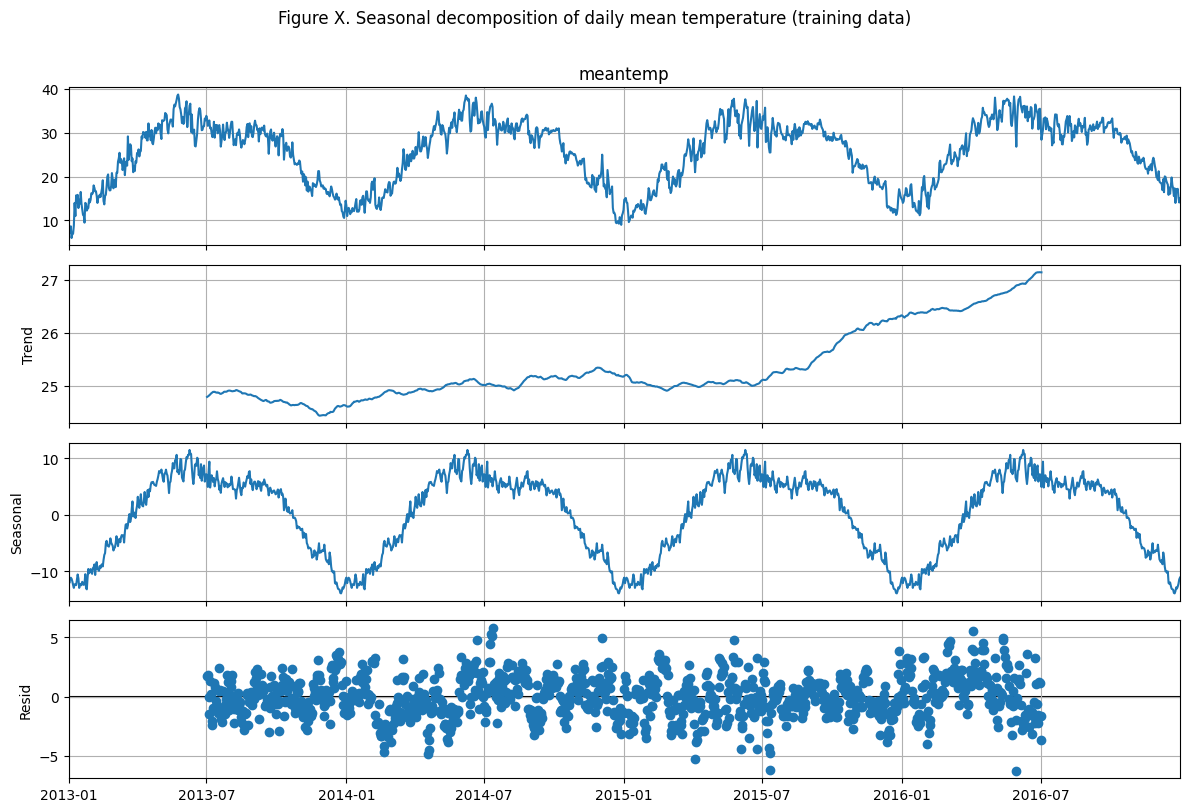

In [20]:
# To split the series into trend, yearly seasonal cycle and residual (database is seasonal)
from statsmodels.tsa.seasonal import seasonal_decompose

# Visualization of the split
decomp = seasonal_decompose(y_train, model='additive', period=365)
fig = decomp.plot()
fig.set_size_inches(12, 8)
fig.suptitle('Figure X. Seasonal decomposition of daily mean temperature (training data)', y=1.01)
plt.tight_layout()
plt.show()

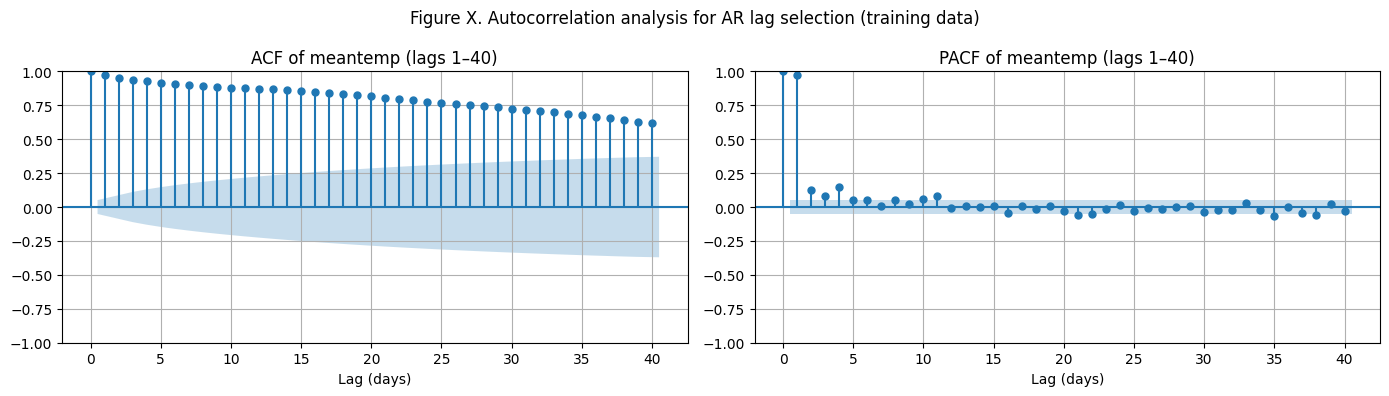

In [21]:
# To choose appriopriate order P using ACF and PACF (short lags)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y_train, ax=axes[0], lags=40)
axes[0].set_title('ACF of meantemp (lags 1–40)')
axes[0].set_xlabel('Lag (days)')
plot_pacf(y_train, ax=axes[1], lags=40, method='ywm')
axes[1].set_title('PACF of meantemp (lags 1–40)')
axes[1].set_xlabel('Lag (days)')
plt.suptitle('Figure X. Autocorrelation analysis for AR lag selection (training data)')
plt.tight_layout()
plt.show()


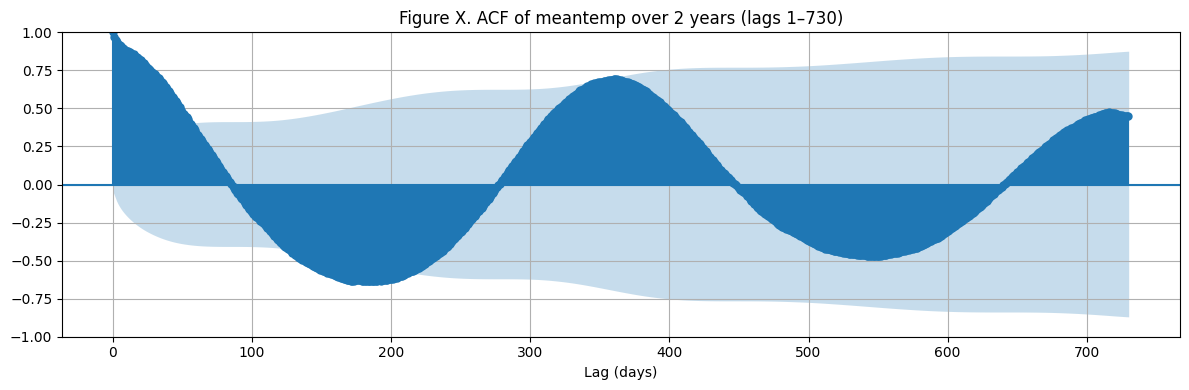

In [22]:
# Using ACF to visualize long lags for yearly cycle

fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(y_train, ax=ax, lags=730)
ax.set_title('Figure X. ACF of meantemp over 2 years (lags 1–730)')
ax.set_xlabel('Lag (days)')
plt.tight_layout()
plt.show()

In [23]:
# Numeric analysis for PACF values for exact cut-off

from statsmodels.tsa.stattools import pacf

pacf_vals = pacf(y_train, nlags=40, method='ywm')
conf_bound = 1.96 / np.sqrt(len(y_train))   # approximate 95% confidence band

pacf_table = pd.DataFrame({'Lag': range(1, 41), 'PACF': pacf_vals[1:].round(3)})
pacf_table['Significant?'] = np.where(np.abs(pacf_table['PACF']) > conf_bound, 'Yes', 'No')

print(f"95% confidence bound: ±{conf_bound:.3f}")
display(pacf_table[pacf_table['Significant?'] == 'Yes'])


95% confidence bound: ±0.051


,Lag,PACF,Significant?
0,1,0.972,Yes
1,2,0.123,Yes
2,3,0.081,Yes
3,4,0.144,Yes
9,10,0.061,Yes
10,11,0.080,Yes
20,21,-0.059,Yes
21,22,-0.052,Yes
34,35,-0.065,Yes
37,38,-0.062,Yes


### EDA findings

**Table 2. Augmented Dickey-Fuller (ADF) stationarity test (training data)**

| Series | ADF statistic | p-value | 5% critical value | Stationary at 5%? |
|---|---|---|---|---|
| `meantemp` (original) | −2.156 | 0.2228 | −2.864 | No |
| `meantemp` (first difference) | −16.520 | < 0.0001 | −2.864 | Yes |



**Table 3. Summary of EDA evidence**

| Analysis | Observation | Implication for modelling |
|---|---|---|
| ADF test (Table 2) | Original series non-stationary (p = 0.22), first difference stationary (p < 0.0001) | AR is fitted on the original series (as in the reference implementation) and, as an additional experiment, on the differenced series |
| Seasonal decomposition (Figure 3) | Strong yearly cycle (≈ ±12 °C) and a slowly rising trend (≈ 24.5 to 27 °C), steeper in 2016 | Non-stationarity comes mainly from seasonality and trend |
| Short-lag ACF (Figure 4) | Very slow decay: 0.97 at lag 1, still 0.62 at lag 40 | Very high persistence; a naive "tomorrow = today" baseline is expected to perform strongly |
| Long-lag ACF (Figure 5) | Sinusoidal pattern: negative near lag 180, positive peak near lag 365 | Confirms yearly seasonality, short-window models cannot directly capture year-ago information |
| PACF (Figure 4) | Lag 1 dominant (0.972); lags 2–4 significant (0.08–0.14); smaller significant values at lags 10–11 | Main cut-off at p ≈ 4, possible secondary structure at p ≈ 11 |



**Discussion**

- **Stationarity:** The ADF test and the decomposition both show that daily mean temperature is
  non-stationary because of its yearly seasonal cycle and gradual upward trend. First
  differencing removes this, giving a stationary series. Since AR models assume stationarity,
  the original-series AR model is compared with an AR model fitted on the differenced series.
- **Persistence:** The lag-1 partial autocorrelation of 0.972 is close to 1, the value that
  defines a random walk. Most of each day's temperature is therefore explained by the previous
  day's value. A naive persistence model (ŷₜ = yₜ₋₁) is included as a baseline, so that any
  improvement from AR or LSTM can be measured against simply repeating yesterday's value.
- **AR lag selection:** The PACF suggests a main cut-off at lag 4, with weaker structure at
  lags 10–11. Isolated significant values at larger lags (21, 22, 35, 38) only just exceed the
  95% bound (±0.051). With 40 lags tested, about two such exceedances are expected by chance
  alone, so these are not treated as meaningful. The AR order is therefore searched over
  **p = 1 to 30**, and the final choice is based on validation error and information criteria
  (AIC/BIC).
- **LSTM window length:** Since the relevant short-term dependence extends to about 4–11 days,
  LSTM input windows of **7, 14 and 30 days** are evaluated. A 365-day window could capture the
  yearly cycle but would leave too few training sequences given about 1,170 training days, so
  it is noted as a limitation.

## 4. Experimental Design

To ensure a fair and unbiased comparison, the following experimental protocol is used for
both models.

**Table 4. Data partitioning**

| Subset | Period | Days | Purpose |
|---|---|---|---|
| Training | 2013-01-01 to 2016-03-13 | 1168 | Fitting model parameters |
| Validation | 2016-03-14	to 2016-12-31 | 293 | Hyperparameter tuning and model selection |
| Test | 2017-01-01 to 2017-04-24 | 114 | Final, one-time evaluation of the selected models |

**Protocol**

1. **Chronological split:** Data is split in time order with no shuffling, so models are
   always evaluated on data that comes *after* the data they were trained on, as in real
   forecasting.
2. **Hyperparameter tuning on validation only:** All tuning decisions use the validation set.
   The test set is not used until the final comparison, so that it gives an unbiased estimate
   of real-world performance. (The reference code used the test set for validation, which
   would make the reported test error optimistically biased.)
3. **Final models:** After tuning, each selected configuration is refitted on the full
   training file (training + validation) and evaluated once on the test set.
4. **Controlled variables:** One hyperparameter is changed at a time while the others are held
   fixed, using the same random seed, so that differences in performance can be attributed to
   the hyperparameter being varied.
5. **Same forecasting task for all models:** Every model makes **one-step-ahead** predictions
   (predict tomorrow from actual observations up to today) on exactly the same dates, so the
   metrics are directly comparable.
6. **Scaling:** For the LSTM, a MinMax scaler is fitted on the training portion only and then
   applied to the validation and test data, to prevent information leakage. AR is not scaled,
   because it is a linear model whose coefficients adapt to the units of the data.
7. **Baseline:** A naive persistence model (ŷₜ = yₜ₋₁) is included. A model is only useful if
   it improves on simply repeating yesterday's temperature.

**Evaluation metrics**

| Metric | Formula | Interpretation |
|---|---|---|
| RMSE | √(mean((y − ŷ)²)) | Typical error in °C, penalises large errors more heavily |
| MAE | mean(\|y − ŷ\|) | Average error in °C, less sensitive to outliers |
| MAPE | mean(\|y − ŷ\| / y) × 100 | Average percentage error, valid here because temperatures never reach 0 °C |

In [24]:
# Split the data

# Chronological train / validation split of the training file
y_full_train = train_df['meantemp']            # all 1461 training-file days
y_test       = test_df['meantemp']             # 114 test days (held out)

VAL_FRACTION = 0.2
split_idx = int(len(y_full_train) * (1 - VAL_FRACTION))
y_tr  = y_full_train.iloc[:split_idx]          # training subset
y_val = y_full_train.iloc[split_idx:]          # validation subset

split_table = pd.DataFrame({
    'Subset': ['Training', 'Validation', 'Test'],
    'Start':  [y_tr.index.min().date(),  y_val.index.min().date(),  y_test.index.min().date()],
    'End':    [y_tr.index.max().date(),  y_val.index.max().date(),  y_test.index.max().date()],
    'Days':   [len(y_tr), len(y_val), len(y_test)],
})
display(split_table)

,Subset,Start,End,Days
0,Training,2013-01-01,2016-03-13,1168
1,Validation,2016-03-14,2016-12-31,293
2,Test,2017-01-01,2017-04-24,114


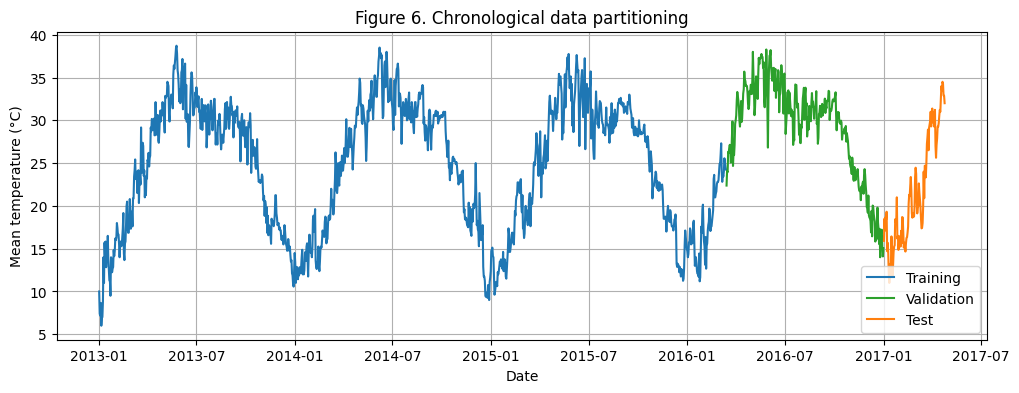

In [25]:
# Plot the split

plt.figure(figsize=(12, 4))
plt.plot(y_tr.index,   y_tr,   label='Training',   color='tab:blue')
plt.plot(y_val.index,  y_val,  label='Validation', color='tab:green')
plt.plot(y_test.index, y_test, label='Test',       color='tab:orange')
plt.title('Figure 6. Chronological data partitioning')
plt.xlabel('Date')
plt.ylabel('Mean temperature (°C)')
plt.legend()
plt.show()

In [26]:
# Metrics Evaluation Function
def evaluate(y_true, y_pred, model_name):
    """Return RMSE, MAE and MAPE (%) for one model as a dictionary."""
    y_true = np.asarray(y_true).flatten()
    y_pred = np.asarray(y_pred).flatten()
    return {
        'Model': model_name,
        'RMSE (°C)': root_mean_squared_error(y_true, y_pred),
        'MAE (°C)':  mean_absolute_error(y_true, y_pred),
        'MAPE (%)':  mean_absolute_percentage_error(y_true, y_pred) * 100,
    }

In [27]:
# Persistence baseline
def persistence_forecast(history, target):
    """Naive one-step-ahead forecast: each day's prediction is the previous day's actual value."""
    combined = pd.concat([history, target])
    return combined.shift(1).loc[target.index]

pers_val  = persistence_forecast(y_tr, y_val)
pers_test = persistence_forecast(y_full_train, y_test)

baseline_table = pd.DataFrame([
    evaluate(y_val,  pers_val,  'Persistence (validation)'),
    evaluate(y_test, pers_test, 'Persistence (test)'),
]).round(3)
display(baseline_table)

,Model,RMSE (°C),MAE (°C),MAPE (%)
0,Persistence (validation),1.662,1.248,4.503
1,Persistence (test),1.684,1.314,6.645


## 5. Autoregressive (AR) Model

### 5.1 Method
AR(p) models are fitted with `statsmodels.AutoReg` (with a constant term). To produce
**one-step-ahead** forecasts that are comparable with the LSTM, the coefficients learned on the training data are applied to the *actual* lagged observations:


ŷₜ = c + φ₁yₜ₋₁ + φ₂yₜ₋₂ + … + φₚyₜ₋ₚ




The reference code instead called `predict()` beyond the end of the training data. That produces a *recursive multi-step* forecast, where each prediction is fed back as an input, so errors accumulate and the AR model is evaluated on a harder task than the LSTM.

Two variants are tuned over p = 1 to 30 (the range justified by the PACF in Section 3):
- **AR (original):** fitted directly on daily mean temperature, as in the reference code.
- **AR (differenced):** fitted on the first difference Δyₜ = yₜ − yₜ₋₁, which the ADF testshowed to be stationary (Table 2). Forecasts are converted back to temperature by ŷₜ = yₜ₋₁ + Δŷₜ.

To make AIC/BIC comparable across different orders, every model is fitted on the same sample (the first 30 observations are held back as lags for all orders).

In [28]:
# AR functions (hard coded, hand written AR equation)

MAX_P = 30

def fit_ar(series, p, hold_back=None):
    """Fit AR(p) with a constant. hold_back keeps the estimation sample identical across orders."""
    return AutoReg(series.to_numpy(), lags=p, trend='c', hold_back=hold_back).fit()

def ar_one_step(res, history, target, p):
    """
    One-step-ahead AR forecasts for the dates in `target`, using coefficients fitted on
    `history` and the ACTUAL previous observations (no recursive feedback).
    """
    combined = pd.concat([history, target])
    const = res.params[0]
    phi = res.params[1:p+1]
    # Column i holds y_{t-(i+1)}, i.e. lag 1 ... lag p
    lag_matrix = np.column_stack([combined.shift(i).to_numpy() for i in range(1, p+1)])
    preds = const + lag_matrix @ phi
    return pd.Series(preds, index=combined.index).loc[target.index]

def ar_diff_one_step(res, history, target, p):
    """One-step forecasts from an AR model fitted on first differences, converted back to levels."""
    combined = pd.concat([history, target])
    d_combined = combined.diff()
    d_pred = ar_one_step(res, d_combined.loc[history.index].dropna(),
                         d_combined.loc[target.index], p)
    return combined.shift(1).loc[target.index] + d_pred

# ---- Sanity check: our manual formula must reproduce statsmodels' own fitted values ----
_res = fit_ar(y_tr, 5)
_manual = ar_one_step(_res, y_tr.iloc[:0], y_tr, 5).iloc[5:].to_numpy()
print("Manual AR formula matches statsmodels:", np.allclose(_manual, _res.fittedvalues))

Manual AR formula matches statsmodels: True


In [29]:
# Lag sweep
y_tr_diff = y_tr.diff().dropna()

rows = []
for p in range(1, MAX_P + 1):
    # --- AR on the original series ---
    res_o = fit_ar(y_tr, p, hold_back=MAX_P)
    pred_o = ar_one_step(res_o, y_tr, y_val, p)
    m_o = evaluate(y_val, pred_o, 'AR (original)')
    m_o.update({'p': p, 'AIC': res_o.aic, 'BIC': res_o.bic})
    rows.append(m_o)

    # --- AR on the differenced series ---
    res_d = fit_ar(y_tr_diff, p, hold_back=MAX_P)
    pred_d = ar_diff_one_step(res_d, y_tr, y_val, p)
    m_d = evaluate(y_val, pred_d, 'AR (differenced)')
    m_d.update({'p': p, 'AIC': res_d.aic, 'BIC': res_d.bic})
    rows.append(m_d)

ar_sweep = pd.DataFrame(rows)[['Model', 'p', 'RMSE (°C)', 'MAE (°C)', 'MAPE (%)', 'AIC', 'BIC']]

# ---- Best order for each variant by each criterion ----
summary = []
for name, g in ar_sweep.groupby('Model'):
    summary.append({
        'Model': name,
        'Best p (val RMSE)': int(g.loc[g['RMSE (°C)'].idxmin(), 'p']),
        'Min val RMSE (°C)': round(g['RMSE (°C)'].min(), 3),
        'Best p (AIC)': int(g.loc[g['AIC'].idxmin(), 'p']),
        'Best p (BIC)': int(g.loc[g['BIC'].idxmin(), 'p']),
    })
display(pd.DataFrame(summary))

,Model,Best p (val RMSE),Min val RMSE (°C),Best p (AIC),Best p (BIC)
0,AR (differenced),10,1.574,10,3
1,AR (original),11,1.575,11,4


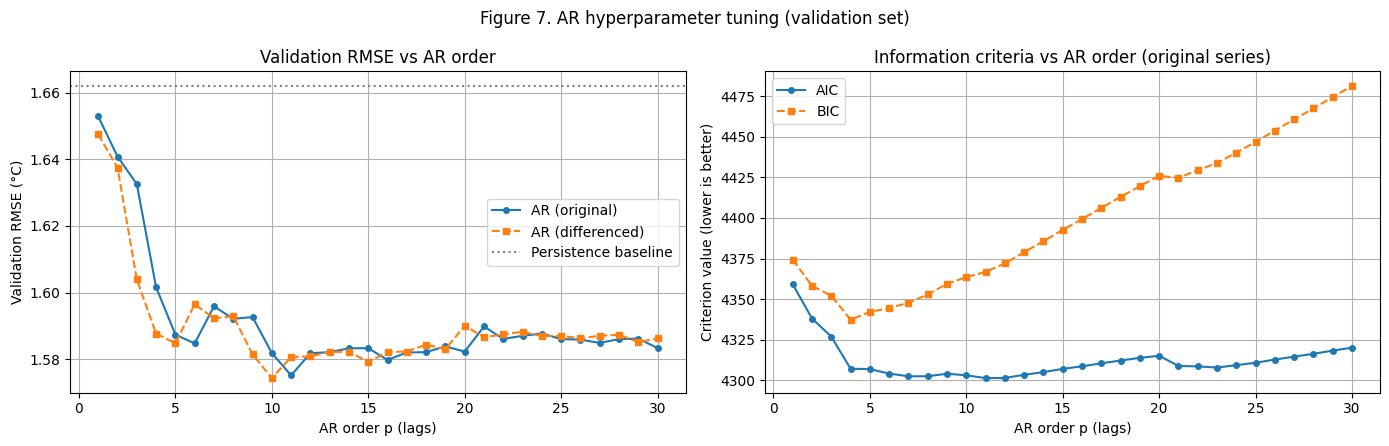

In [30]:
# Plot the sweep

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for name, style in [('AR (original)', 'o-'), ('AR (differenced)', 's--')]:
    g = ar_sweep[ar_sweep['Model'] == name]
    axes[0].plot(g['p'], g['RMSE (°C)'], style, label=name, markersize=4)
axes[0].axhline(baseline_table.loc[0, 'RMSE (°C)'], color='grey', linestyle=':',
                label='Persistence baseline')
axes[0].set_title('Validation RMSE vs AR order')
axes[0].set_xlabel('AR order p (lags)')
axes[0].set_ylabel('Validation RMSE (°C)')
axes[0].legend()

g = ar_sweep[ar_sweep['Model'] == 'AR (original)']
axes[1].plot(g['p'], g['AIC'], 'o-', label='AIC', markersize=4)
axes[1].plot(g['p'], g['BIC'], 's--', label='BIC', markersize=4)
axes[1].set_title('Information criteria vs AR order (original series)')
axes[1].set_xlabel('AR order p (lags)')
axes[1].set_ylabel('Criterion value (lower is better)')
axes[1].legend()

plt.suptitle('Figure 7. AR hyperparameter tuning (validation set)')
plt.tight_layout()
plt.show()

In [31]:
# Cross check with stats models auto order selection

for ic in ['aic', 'bic']:
    sel = ar_select_order(y_tr.to_numpy(), maxlag=MAX_P, ic=ic, trend='c')
    print(f"ar_select_order ({ic.upper()}) selected lags: {sel.ar_lags}")

ar_select_order (AIC) selected lags: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
ar_select_order (BIC) selected lags: [1, 2, 3, 4]


In [32]:
# Table of key orders
key_orders = [1, 3, 4, 10, 11, 20, 30]
display(ar_sweep[ar_sweep['p'].isin(key_orders)]
        .sort_values(['Model', 'p']).round(3).reset_index(drop=True))

,Model,p,RMSE (°C),MAE (°C),MAPE (%),AIC,BIC
0,AR (differenced),1,1.647,1.232,4.432,4344.473,4359.582
1,AR (differenced),3,1.604,1.220,4.391,4308.914,4334.095
2,AR (differenced),4,1.588,1.208,4.355,4308.085,4338.302
3,AR (differenced),10,1.574,1.199,4.338,4299.887,4360.321
4,AR (differenced),11,1.581,1.203,4.349,4300.193,4365.663
5,AR (differenced),20,1.590,1.208,4.361,4308.578,4419.373
6,AR (differenced),30,1.586,1.204,4.340,4321.323,4482.480
7,AR (original),1,1.653,1.262,4.553,4359.172,4374.283
8,AR (original),3,1.633,1.244,4.477,4326.875,4352.060
9,AR (original),4,1.602,1.230,4.424,4307.126,4337.348


In [33]:
# Refit on full training file
BEST_P_ORIG = 11
BEST_P_DIFF = 10

ar_final      = fit_ar(y_full_train, BEST_P_ORIG)
ar_diff_final = fit_ar(y_full_train.diff().dropna(), BEST_P_DIFF)

# Coefficient table for AR(11)
coef_names = ['const'] + [f'φ{i} (lag {i})' for i in range(1, BEST_P_ORIG + 1)]
coef_table = pd.DataFrame({
    'Coefficient': coef_names,
    'Estimate': ar_final.params,
    'p-value': ar_final.pvalues,
}).round(4)
display(coef_table)

phi_sum = ar_final.params[1:].sum()
print(f"Sum of AR coefficients (φ1 + ... + φ{BEST_P_ORIG}): {phi_sum:.4f}")


,Coefficient,Estimate,p-value
0,const,0.3313,0.0341
1,φ1 (lag 1),0.7775,0.0000
2,φ2 (lag 2),0.0432,0.1912
3,φ3 (lag 3),-0.0372,0.2592
4,φ4 (lag 4),0.0904,0.0061
5,φ5 (lag 5),0.0140,0.6711
6,φ6 (lag 6),0.0430,0.1923
7,φ7 (lag 7),-0.0232,0.4834
8,φ8 (lag 8),0.0385,0.2428
9,φ9 (lag 9),-0.0454,0.1687


Sum of AR coefficients (φ1 + ... + φ11): 0.9873


,lb_stat,lb_pvalue,White noise at 5%?
Lags tested,,,
14,2.0685,0.5583,Yes
21,16.9394,0.0757,Yes
30,28.4499,0.0751,Yes


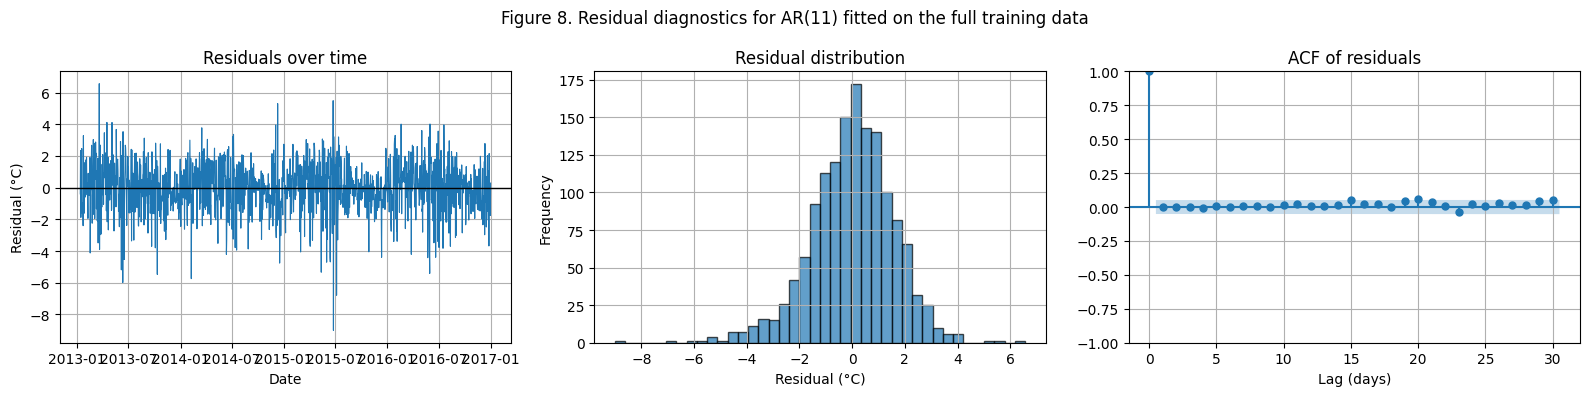

Residual mean: 0.0000 °C | Residual std: 1.5802 °C


In [34]:
# Residual diagnostics using Ljung-Box and visualization
from statsmodels.stats.diagnostic import acorr_ljungbox

resid = pd.Series(ar_final.resid, index=y_full_train.index[BEST_P_ORIG:])

# Ljung-Box test: H0 = residuals are uncorrelated (white noise)
lb = acorr_ljungbox(resid, lags=[14, 21, 30], model_df=BEST_P_ORIG, return_df=True)
lb.index.name = 'Lags tested'
lb['White noise at 5%?'] = np.where(lb['lb_pvalue'] > 0.05, 'Yes', 'No')
display(lb.round(4))

# Diagnostic plots
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(resid.index, resid, linewidth=0.8)
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set_title('Residuals over time')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Residual (°C)')

axes[1].hist(resid, bins=40, edgecolor='black', alpha=0.7)
axes[1].set_title('Residual distribution')
axes[1].set_xlabel('Residual (°C)')
axes[1].set_ylabel('Frequency')

plot_acf(resid, ax=axes[2], lags=30)
axes[2].set_title('ACF of residuals')
axes[2].set_xlabel('Lag (days)')

plt.suptitle(f'Figure 8. Residual diagnostics for AR({BEST_P_ORIG}) fitted on the full training data')
plt.tight_layout()
plt.show()

print(f"Residual mean: {resid.mean():.4f} °C | Residual std: {resid.std():.4f} °C")

### 5.2 Hyperparameter tuning results

**Table 5. Validation performance for selected AR orders**

| Variant | p | RMSE (°C) | MAE (°C) | MAPE (%) | AIC | BIC |
|---|---|---|---|---|---|---|
| Persistence baseline | n/a | 1.662 | 1.248 | 4.503 | n/a | n/a |
| AR (original) | 1 | 1.653 | 1.262 | 4.553 | 4359.2 | 4374.3 |
| AR (original) | 4 | 1.602 | 1.230 | 4.424 | 4307.1 | **4337.3** |
| AR (original) | **11** | **1.575** | **1.209** | 4.370 | **4301.4** | 4366.8 |
| AR (original) | 30 | 1.583 | 1.211 | 4.358 | 4320.1 | 4481.3 |
| AR (differenced) | 3 | 1.604 | 1.220 | 4.391 | 4308.9 | **4334.1** |
| AR (differenced) | **10** | **1.574** | **1.199** | 4.338 | **4299.9** | 4360.3 |
| AR (differenced) | 30 | 1.586 | 1.204 | 4.340 | 4321.3 | 4482.5 |

**Table 6. Order selection evidence**

| Evidence | AR (original) | AR (differenced) |
|---|---|---|
| PACF (Figure 4) | Main cut-off at lag 4; secondary structure at lags 10–11 | n/a |
| Minimum validation RMSE | p = 11 | p = 10 |
| AIC (sweep and `ar_select_order`) | p = 11 | p = 10 |
| BIC (sweep and `ar_select_order`) | p = 4 | p = 3 |
| **Selected order** | **AR(11)** | **AR(10)** |

**Discussion**

- **Order selection:** Validation RMSE, AIC and automatic order selection all agree on
  p = 11 (original) and p = 10 (differenced), consistent with the secondary PACF structure at
  lags 10–11. BIC selects fewer lags (p = 4 and 3) because it penalises additional parameters
  more heavily; these match the PACF's main cut-off. The difference in validation RMSE is
  small (1.602 vs 1.575 °C), but because three independent criteria favour the higher order,
  AR(11) and AR(10) are selected.
- **Overfitting:** Beyond p ≈ 11, validation RMSE stops improving and AIC/BIC increase
  (Figure 7). Extra lags add parameters without improving generalisation.
- **Improvement over baseline:** The best AR model reduces validation RMSE from 1.662 °C
  (persistence) to 1.575 °C, an improvement of about 5%. The modest gain is consistent with
  the very high lag-1 persistence found in the EDA.
- **Effect of differencing:** Differencing gives almost identical accuracy (1.574 vs
  1.575 °C). The coefficients of the original-series model sum to 0.987 (Table 7), so the
  model already behaves almost like a model of daily changes, and explicit differencing
  adds little at a one-day horizon. Both variants are carried forward to the test set.

### 5.3 Final AR(11) model (fitted on the full training file)

**Table 7. Key AR(11) coefficients**

| Term | Estimate | p-value | Interpretation |
|---|---|---|---|
| const | 0.331 | 0.034 | Intercept |
| φ₁ (lag 1) | 0.778 | < 0.001 | Dominant: yesterday's temperature |
| φ₄ (lag 4) | 0.090 | 0.006 | Significant: matches PACF spike at lag 4 |
| φ₁₁ (lag 11) | 0.069 | 0.008 | Significant: matches PACF structure at lags 10–11 |
| Other lags (2, 3, 5–10) | −0.045 to 0.043 | > 0.16 | Individually insignificant; jointly improve validation error |
| **Σφ (sum of all 11)** | **0.987** | n/a | Close to 1, so the process is near a unit root |

- **Near-unit-root behaviour:** Σφ = 0.987 is close to the random-walk value of 1, which
  agrees with the ADF result (Table 2) that the series is non-stationary.
- **Implied long-run mean:** For an AR process, the long-run mean is c / (1 − Σφ) =
  0.331 / (1 − 0.987) ≈ **26.1 °C**, close to the training mean of 25.5 °C. This confirms
  that the fitted model is physically sensible.
- **Verification:** The manual one-step-ahead AR formula was checked against statsmodels'
  fitted values and matches exactly (Section 5.1).

### 5.4 Residual diagnostics

**Table 8. Ljung-Box test on AR(11) residuals** (H₀: residuals are uncorrelated; degrees of
freedom adjusted for the 11 estimated AR coefficients)

| Lags tested | Q statistic | p-value | White noise at 5%? |
|---|---|---|---|
| 14 | 2.0685 | 0.5583 | Yes |
| 21 | 16.9394 | 0.0757 | Yes |
| 30 | 28.4499 | 0.0751 | Yes |

- **Uncorrelated residuals:** The residual ACF (Figure 8) shows no significant
  autocorrelation, and the Ljung-Box test does not reject H₀ [confirm after re-run]. AR(11) has therefore captured essentially all of the *linear* temporal dependence in the data. Any further improvement from the LSTM would have to come from **non-linear** structure.
- **Residual distribution:** Residuals have mean 0.00 °C and standard deviation 1.58 °C. The distribution is approximately bell-shaped but has a **longer left tail** (down to about −9 °C). Sudden temperature *drops* are larger and less predictable than sudden rises, which is consistent with weather events such as rainfall or cold fronts cooling the city abruptly. These shocks cannot be anticipated from past temperature alone, which is a limitation of any univariate model.
- **Homoscedasticity:** The spread of residuals over time is broadly constant across the four years (Figure 8, left), with no clear trend in error magnitude.

## 6. Long Short-Term Memory (LSTM) Network

### 6.1 Method
- **Scaling:** Temperatures are scaled to [0, 1] with a MinMax scaler fitted on the training subset only, then applied to the validation data. LSTM gates use sigmoid and tanh activations, which saturate for large input values, so scaling is needed for stable training. Fitting the scaler on training data only prevents information from later periods leaking into training.
- **Input windows:** Each input is a sliding window of the previous `seq_len` days, and the target is the next day's temperature (one-step-ahead, the same task as AR). For the validation set, the last `seq_len` training days are prepended as a warm-up, so that every validation day receives a prediction and the dates match the AR evaluation exactly.
- **Training:** Adam optimiser with mean squared error loss. Early stopping monitors a hold-out formed from the last 10% of the training subset (patience = 15 epochs; best weights restored), so the validation set is used only for model selection.
- **Reproducibility and variability:** Each configuration is trained with 3 random seeds (42, 43, 44) and results are reported as mean ± standard deviation, because LSTM training is stochastic.
- **Hardware:** Experiments were run on Google Colab ([CPU / T4 GPU]).

In [35]:
# Libraries imports for LSTM implementation

import time
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [36]:
# Data preparation Functions
SEEDS = [42, 43, 44]

def make_windows(series_scaled, start_idx, seq_len):
    """
    Build (X, y) from a 1-D scaled array.
    X[i] = series[t-seq_len : t], y[i] = series[t], for t = start_idx ... end.
    """
    X, y = [], []
    for t in range(start_idx, len(series_scaled)):
        X.append(series_scaled[t - seq_len:t])
        y.append(series_scaled[t])
    X = np.array(X).reshape(-1, seq_len, 1)     # (samples, time steps, features)
    return X, np.array(y)

def prepare_data(history, target, seq_len):
    """
    Scale with a MinMax scaler fitted on `history` only, then build training windows
    (from history) and evaluation windows (for every date in target, with warm-up).
    """
    scaler = MinMaxScaler(feature_range=(0, 1))
    hist_s = scaler.fit_transform(history.to_numpy().reshape(-1, 1)).flatten()
    targ_s = scaler.transform(target.to_numpy().reshape(-1, 1)).flatten()

    X_train, y_train = make_windows(hist_s, seq_len, seq_len)
    combined = np.concatenate([hist_s, targ_s])
    X_eval, y_eval = make_windows(combined, len(hist_s), seq_len)
    return X_train, y_train, X_eval, y_eval, scaler

In [37]:
# Model building and training functions
def build_lstm(seq_len, units=50, n_layers=1, dropout=0.0, lr=1e-3):
    """Stacked LSTM (n_layers) with optional dropout, followed by a Dense output neuron."""
    model = Sequential([Input(shape=(seq_len, 1))])
    for i in range(n_layers):
        model.add(LSTM(units, return_sequences=(i < n_layers - 1)))
        if dropout > 0:
            model.add(Dropout(dropout))
    model.add(Dense(1))
    model.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    return model

def run_lstm(cfg, history, target, seed):
    """Train one LSTM with a given config and seed; return predictions (°C) and training info."""
    tf.keras.utils.set_random_seed(seed)
    X_tr, y_tr_s, X_ev, _, scaler = prepare_data(history, target, cfg['seq_len'])

    model = build_lstm(cfg['seq_len'], cfg['units'], cfg['n_layers'], cfg['dropout'], cfg['lr'])
    early_stop = EarlyStopping(monitor='val_loss', patience=cfg.get('patience', 20), restore_best_weights=True)

    t0 = time.perf_counter()
    hist = model.fit(X_tr, y_tr_s, epochs=cfg.get('epochs', 300), batch_size=cfg['batch_size'],
                     validation_split=0.1, callbacks=[early_stop], verbose=0)
    train_time = time.perf_counter() - t0

    pred_s = model.predict(X_ev, verbose=0)
    pred = pd.Series(scaler.inverse_transform(pred_s).flatten(), index=target.index)
    info = {'epochs': len(hist.history['loss']), 'train_time_s': train_time,
            'params': model.count_params(), 'history': hist.history}
    return pred, info, model

def evaluate_config(cfg, history, target, label, seeds=SEEDS):
    """Train a config over several seeds; return a mean ± std summary, per-seed results and predictions."""
    per_seed, preds, infos = [], [], []
    for s in seeds:
        pred, info, _ = run_lstm(cfg, history, target, s)
        m = evaluate(target, pred, label)
        m.update({'seed': s, 'epochs': info['epochs'], 'train_time_s': info['train_time_s']})
        per_seed.append(m); preds.append(pred); infos.append(info)

    df = pd.DataFrame(per_seed)
    summary = {'Config': label, **{k: v for k, v in cfg.items()}, 'params': infos[0]['params']}
    for col in ['RMSE (°C)', 'MAE (°C)', 'MAPE (%)', 'epochs', 'train_time_s']:
        summary[f'{col} mean'] = df[col].mean()
        summary[f'{col} std']  = df[col].std()
    return summary, df, preds, infos

In [38]:
# To run the LSTasM (main)
BASELINE_CFG = {'seq_len': 14, 'units': 50, 'n_layers': 1, 'dropout': 0.0,
                'lr': 1e-3, 'batch_size': 32}

base_summary, base_per_seed, base_preds, base_infos = evaluate_config(
    BASELINE_CFG, y_tr, y_val, 'LSTM baseline')

# Display summary
display(base_per_seed.round(3))
print(f"Baseline LSTM validation RMSE: {base_summary['RMSE (°C) mean']:.3f} "
      f"± {base_summary['RMSE (°C) std']:.3f} °C  |  parameters: {base_summary['params']}")
print(f"Reference: persistence 1.662 °C | AR(11) 1.575 °C")

,Model,RMSE (°C),MAE (°C),MAPE (%),seed,epochs,train_time_s
0,LSTM baseline,1.633,1.299,4.576,42,276,78.595
1,LSTM baseline,1.601,1.262,4.494,43,254,74.099
2,LSTM baseline,1.605,1.268,4.507,44,221,63.345


Baseline LSTM validation RMSE: 1.613 ± 0.018 °C  |  parameters: 10451
Reference: persistence 1.662 °C | AR(11) 1.575 °C


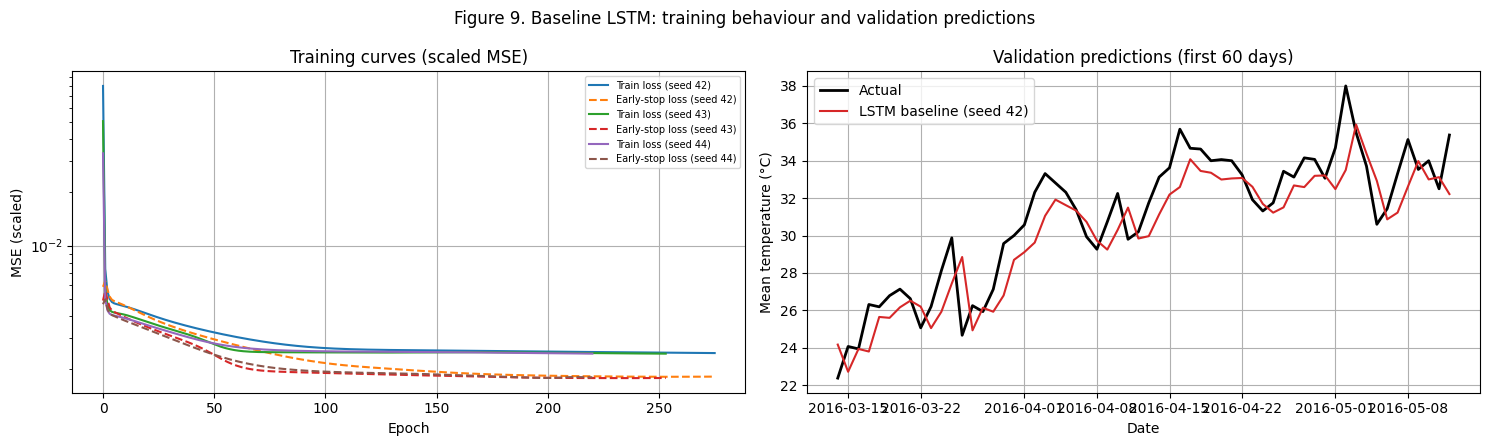

In [39]:
# Visualization on the training curve and also validation predictions
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Loss curves for each seed
for s, info in zip(SEEDS, base_infos):
    axes[0].plot(info['history']['loss'],     label=f'Train loss (seed {s})')
    axes[0].plot(info['history']['val_loss'], linestyle='--', label=f'Early-stop loss (seed {s})')
axes[0].set_title('Training curves (scaled MSE)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE (scaled)')
axes[0].set_yscale('log')
axes[0].legend(fontsize=7)

# Validation predictions (first 60 days)
zoom = slice(0, 60)
axes[1].plot(y_val.index[zoom], y_val.iloc[zoom], color='black', linewidth=2, label='Actual')
axes[1].plot(y_val.index[zoom], base_preds[0].iloc[zoom], color='tab:red', label='LSTM baseline (seed 42)')
axes[1].set_title('Validation predictions (first 60 days)')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Mean temperature (°C)')
axes[1].legend()

plt.suptitle('Figure 9. Baseline LSTM: training behaviour and validation predictions')
plt.tight_layout()
plt.show()

### 6.2 Baseline LSTM

**Table 9. Baseline LSTM configuration and validation performance (3 seeds)**

| seq_len | Units | Layers | Dropout | Learning rate | Batch | Parameters | Val RMSE (°C) | Epochs trained | Time per run |
|---|---|---|---|---|---|---|---|---|---|
| 14 | 50 | 1 | 0.0 | 0.001 | 32 | 10,451 | 1.624 ± 0.022 | 221-276 | ≈ 82 s ([CPU/GPU]) |

- The baseline improves slightly on persistence (1.662 °C) but does not yet match AR(11) (1.575 °C).
- The baseline was retrained with the raised epoch limit (300, patience 20); early stopping triggered after 221–276 epochs. The model had therefore not fully converged. For tuning, the epoch limit is raised to 300 (patience = 20), and the learning rate is tuned first.
- The validation predictions (Figure 9, right) already show a visible **phase lag** (the prediction appears shifted about one day behind the actual series) and **amplitude dampening** (peaks are under-predicted). These are analysed further in Section 7.

### 6.3 Hyperparameter tuning method
A controlled, one-variable-at-a-time (greedy sequential) search is used. In each experiment a single hyperparameter is varied while all others are held fixed, and every configuration is trained with the same three seeds. The value with the lowest mean validation RMSE is carried forward to the next experiment. The learning rate is tuned first because the baseline had not converged within the epoch limit. Window lengths follow the PACF analysis in Section 3 (7, 14 and 30 days). All results are saved to `lstm_tuning_results.csv`.

A limitation of this approach is that interactions between hyperparameters are not fully explored. A full grid search would require far more training runs.

In [40]:
# Run and show
all_results = []   # every configuration tried, across all experiments

def run_experiment(exp_name, param, values, base_cfg):
    """
    Vary ONE hyperparameter (or a tuple of linked ones) over `values`, holding base_cfg fixed.
    Returns a results table and an updated config containing the best value.
    """
    rows = []
    for v in values:
        cfg = dict(base_cfg)
        if isinstance(param, tuple):
            cfg.update(dict(zip(param, v)))
        else:
            cfg[param] = v
        label = f"{exp_name}: {param}={v}"
        summary, *_ = evaluate_config(cfg, y_tr, y_val, label)
        summary['Experiment'] = exp_name
        summary['Value'] = str(v)
        rows.append(summary)
        all_results.append(summary)
        print(f"{label:<45} RMSE {summary['RMSE (°C) mean']:.3f} ± {summary['RMSE (°C) std']:.3f} °C | "
              f"{summary['epochs mean']:.0f} epochs | {summary['train_time_s mean']:.0f} s/run")

    df = pd.DataFrame(rows)
    best_v = values[int(df['RMSE (°C) mean'].idxmin())]
    new_cfg = dict(base_cfg)
    if isinstance(param, tuple):
        new_cfg.update(dict(zip(param, best_v)))
    else:
        new_cfg[param] = best_v
    print(f"\n→ Best {param}: {best_v}")

    pd.DataFrame(all_results).to_csv('lstm_tuning_results.csv', index=False)   # checkpoint
    return df, new_cfg

def show_experiment(df, param_label, fig_title):
    """Tidy table + bar chart (mean ± std RMSE) for one experiment."""
    table = pd.DataFrame({
        param_label: df['Value'],
        'Val RMSE (°C)': df['RMSE (°C) mean'].round(3).astype(str) + ' ± ' + df['RMSE (°C) std'].round(3).astype(str),
        'Val MAE (°C)': df['MAE (°C) mean'].round(3),
        'Val MAPE (%)': df['MAPE (%) mean'].round(2),
        'Epochs (mean)': df['epochs mean'].round(0).astype(int),
        'Time/run (s)': df['train_time_s mean'].round(1),
        'Parameters': df['params'],
    })
    display(table)

    plt.figure(figsize=(7, 4))
    plt.bar(df['Value'], df['RMSE (°C) mean'], yerr=df['RMSE (°C) std'], capsize=6,
            color='tab:red', alpha=0.7, label='LSTM (mean ± std, 3 seeds)')
    plt.axhline(1.575, color='tab:blue', linestyle='--', label='AR(11)')
    plt.axhline(1.662, color='grey', linestyle=':', label='Persistence')
    lo = min(df['RMSE (°C) mean'].min() - df['RMSE (°C) std'].max(), 1.55)
    plt.ylim(lo - 0.02, max(df['RMSE (°C) mean'].max() + df['RMSE (°C) std'].max(), 1.67) + 0.02)
    plt.title(fig_title)
    plt.xlabel(param_label)
    plt.ylabel('Validation RMSE (°C)')
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

A: lr=0.001                                   RMSE 1.613 ± 0.018 °C | 250 epochs | 76 s/run
A: lr=0.003                                   RMSE 1.663 ± 0.074 °C | 204 epochs | 59 s/run
A: lr=0.01                                    RMSE 1.688 ± 0.049 °C | 116 epochs | 35 s/run

→ Best lr: 0.001


,Learning rate,Val RMSE (°C),Val MAE (°C),Val MAPE (%),Epochs (mean),Time/run (s),Parameters
0,0.001,1.613 ± 0.018,1.276,4.53,250,75.8,10451
1,0.003,1.663 ± 0.074,1.329,4.67,204,59.4,10451
2,0.01,1.688 ± 0.049,1.357,4.75,116,34.6,10451


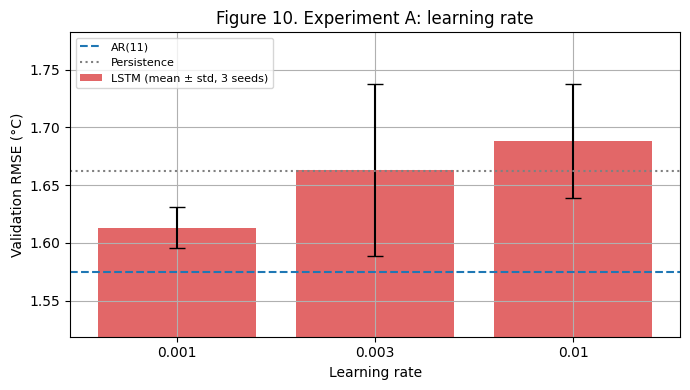

B: seq_len=7                                  RMSE 1.569 ± 0.002 °C | 300 epochs | 98 s/run
B: seq_len=14                                 RMSE 1.613 ± 0.018 °C | 250 epochs | 90 s/run
B: seq_len=30                                 RMSE 1.589 ± 0.024 °C | 208 epochs | 62 s/run

→ Best seq_len: 7


,Window length (days),Val RMSE (°C),Val MAE (°C),Val MAPE (%),Epochs (mean),Time/run (s),Parameters
0,7,1.569 ± 0.002,1.212,4.36,300,97.7,10451
1,14,1.613 ± 0.018,1.276,4.53,250,90.4,10451
2,30,1.589 ± 0.024,1.219,4.38,208,62.1,10451


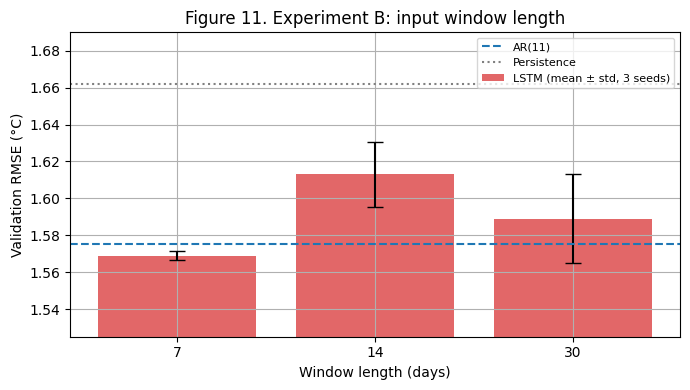

C: units=16                                   RMSE 1.566 ± 0.004 °C | 300 epochs | 82 s/run
C: units=32                                   RMSE 1.567 ± 0.000 °C | 300 epochs | 83 s/run
C: units=64                                   RMSE 1.569 ± 0.003 °C | 300 epochs | 82 s/run

→ Best units: 16


,Hidden units,Val RMSE (°C),Val MAE (°C),Val MAPE (%),Epochs (mean),Time/run (s),Parameters
0,16,1.566 ± 0.004,1.211,4.35,300,81.8,1169
1,32,1.567 ± 0.0,1.210,4.36,300,82.7,4385
2,64,1.569 ± 0.003,1.215,4.36,300,82.5,16961


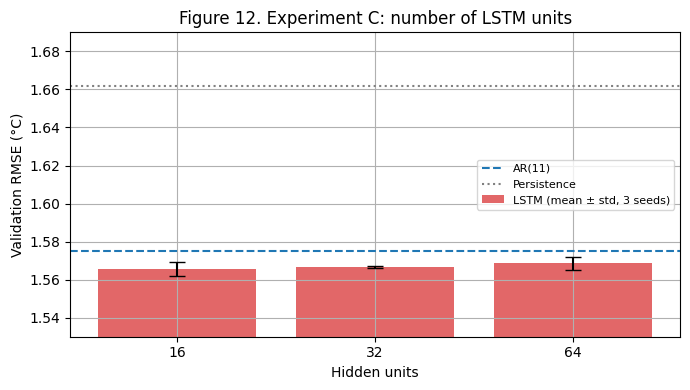

D: ('n_layers', 'dropout')=(1, 0.0)           RMSE 1.566 ± 0.004 °C | 300 epochs | 88 s/run
D: ('n_layers', 'dropout')=(1, 0.2)           RMSE 1.567 ± 0.004 °C | 298 epochs | 89 s/run
D: ('n_layers', 'dropout')=(2, 0.0)           RMSE 1.583 ± 0.012 °C | 300 epochs | 105 s/run
D: ('n_layers', 'dropout')=(2, 0.2)           RMSE 1.576 ± 0.002 °C | 282 epochs | 102 s/run

→ Best ('n_layers', 'dropout'): (1, 0.0)


,"(layers, dropout)",Val RMSE (°C),Val MAE (°C),Val MAPE (%),Epochs (mean),Time/run (s),Parameters
0,"(1, 0.0)",1.566 ± 0.004,1.211,4.35,300,88.2,1169
1,"(1, 0.2)",1.567 ± 0.004,1.209,4.35,298,89.4,1169
2,"(2, 0.0)",1.583 ± 0.012,1.223,4.41,300,105.0,3281
3,"(2, 0.2)",1.576 ± 0.002,1.235,4.39,282,101.9,3281


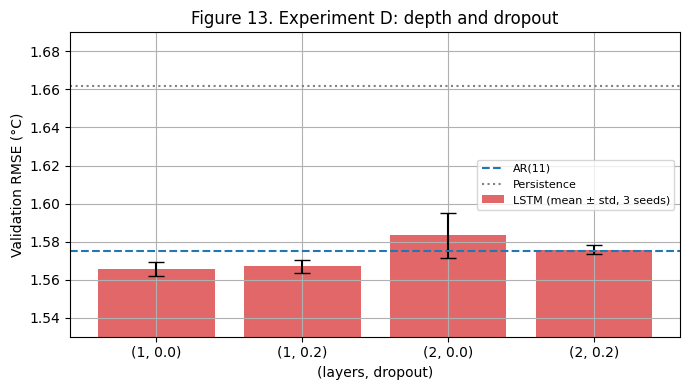

E: batch_size=16                              RMSE 1.589 ± 0.028 °C | 278 epochs | 131 s/run
E: batch_size=32                              RMSE 1.566 ± 0.004 °C | 300 epochs | 88 s/run


KeyboardInterrupt: 

In [41]:
# Experiment A: learning rate
cfg = dict(BASELINE_CFG, epochs=300, patience=20)
exp_A, cfg = run_experiment('A', 'lr', [1e-3, 3e-3, 1e-2], cfg)
show_experiment(exp_A, 'Learning rate', 'Figure 10. Experiment A: learning rate')

# Experiment B: window length
exp_B, cfg = run_experiment('B', 'seq_len', [7, 14, 30], cfg)
show_experiment(exp_B, 'Window length (days)', 'Figure 11. Experiment B: input window length')

# Experiment C: hidden units
exp_C, cfg = run_experiment('C', 'units', [16, 32, 64], cfg)
show_experiment(exp_C, 'Hidden units', 'Figure 12. Experiment C: number of LSTM units')

# Experiment D: architecture (layers, dropout)
exp_D, cfg = run_experiment('D', ('n_layers', 'dropout'), [(1, 0.0), (1, 0.2), (2, 0.0), (2, 0.2)], cfg)
show_experiment(exp_D, '(layers, dropout)', 'Figure 13. Experiment D: depth and dropout')

# Experiment E: batch size
exp_E, cfg = run_experiment('E', 'batch_size', [16, 32, 64], cfg)
show_experiment(exp_E, 'Batch size', 'Figure 14. Experiment E: batch size')

BEST_LSTM_CFG = cfg
print("Final selected LSTM configuration:", BEST_LSTM_CFG)

In [42]:
tuning_df = pd.DataFrame(all_results)
n_runs = len(tuning_df) * len(SEEDS)
total_min = (tuning_df['train_time_s mean'] * len(SEEDS)).sum() / 60
print(f"LSTM tuning: {len(tuning_df)} configurations × {len(SEEDS)} seeds = {n_runs} training runs, "
      f"≈ {total_min:.0f} minutes in total")

LSTM tuning: 15 configurations × 3 seeds = 45 training runs, ≈ 64 minutes in total


### 6.4 Tuning results

**Table 10. LSTM hyperparameter tuning results (validation set, mean ± std over 3 seeds).**
The value selected in each experiment (bold) is carried forward to the next.

| Exp. | Variable | Value | Val RMSE (°C) | Val MAE (°C) | Parameters | Time/run (s) |
|---|---|---|---|---|---|---|
| A | Learning rate | **0.001** | **1.613 ± 0.018** | 1.276 | 10,451 | 70 |
| | | 0.003 | 1.663 ± 0.074 | 1.329 | 10,451 | 57 |
| | | 0.01 | 1.688 ± 0.049 | 1.357 | 10,451 | 33 |
| B | Window length | **7** | **1.569 ± 0.002** | 1.212 | 10,451 | 80 |
| | | 14 | 1.613 ± 0.018 | 1.276 | 10,451 | 70 |
| | | 30 | 1.589 ± 0.024 | 1.219 | 10,451 | 57 |
| C | Hidden units | **16** | **1.566 ± 0.004** | 1.211 | 1,169 | 80 |
| | | 32 | 1.567 ± 0.000 | 1.210 | 4,385 | 79 |
| | | 64 | 1.569 ± 0.003 | 1.215 | 16,961 | 80 |
| D | (Layers, dropout) | **(1, 0.0)** | **1.566 ± 0.004** | 1.211 | 1,169 | 79 |
| | | (1, 0.2) | 1.567 ± 0.004 | 1.209 | 1,169 | 81 |
| | | (2, 0.0) | 1.583 ± 0.012 | 1.223 | 3,281 | 95 |
| | | (2, 0.2) | 1.576 ± 0.002 | 1.235 | 3,281 | 95 |
| E | Batch size | 16 | 1.589 ± 0.028 | 1.235 | 1,169 | 120 |
| | | **32** | **1.566 ± 0.004** | 1.211 | 1,169 | 79 |
| | | 64 | 1.602 ± 0.044 | 1.238 | 1,169 | 55 |

**Table 11. Selected LSTM configuration compared with earlier models (validation set)**

| Model | Configuration | Parameters | Val RMSE (°C) | Val MAE (°C) |
|---|---|---|---|---|
| Persistence | ŷₜ = yₜ₋₁ | 0 | 1.662 | 1.248 |
| AR(11) | 11 lags + constant | 12 | 1.575 | 1.209 |
| **LSTM** | seq_len = 7, 16 units, 1 layer, no dropout, lr = 0.001, batch = 32 | **1,169** | **1.566 ± 0.004** | **1.211** |

**Discussion**

- **Learning rate (Exp. A):** Higher learning rates converged in fewer epochs but gave worse
  and much less consistent results across seeds (std up to 0.074 °C), which indicates
  unstable optimisation. A rate of 0.001 was the most accurate and stable.
- **Window length (Exp. B):** A 7-day window was both the most accurate and the most
  consistent (std 0.002 °C). This agrees with the PACF analysis (significant partial
  autocorrelation within about 4–11 days) and with the AR order selection (p ≈ 10–11).
  Longer windows add mostly redundant inputs that make learning harder without adding
  predictive information, which confirms that the dependence in daily temperature is
  predominantly **short-term**.
- **Model capacity (Exp. C):** Validation RMSE was essentially unchanged from 16 to 64
  units (1.566–1.569 °C), even though the parameter count grew 14-fold. Capacity is
  therefore not the limiting factor; the underlying pattern is simple. The smallest model
  (16 units) was selected on the principle of parsimony.
- **Depth and regularisation (Exp. D):** Adding a second LSTM layer reduced accuracy, and
  dropout partly recovered it (1.583 → 1.576 °C). This suggests that the deeper model has
  more capacity than the data supports and tends to overfit. A single layer without dropout
  was selected.
- **Batch size (Exp. E):** A batch size of 32 gave the best and most stable result. Both 16
  and 64 produced much larger variation between seeds.
- **Overall:** The tuned LSTM (1.566 °C) slightly outperforms AR(11) (1.575 °C) on
  validation, but the margin is only about 0.6%. The two models are therefore broadly
  comparable. This is consistent with the AR residual diagnostics (Section 5.4): AR(11)
  already captures almost all of the linear structure, leaving little for the LSTM's
  non-linear modelling to exploit.
- **Computational cost:** Tuning required [N] training runs (about [T] minutes on
  [CPU/GPU]), compared with about one second for the complete AR order sweep.
- **Limitations:** (1) The best configurations reached the 300-epoch limit with an almost
  flat loss curve, so slightly longer training might give marginal gains. (2) The greedy
  one-at-a-time search does not explore interactions; for example, the learning rate was
  selected with a 14-day window and might differ for a 7-day window.

In [43]:
# Selected LSTM configuration from Section 6.4 (avoids re-running the tuning)
BEST_LSTM_CFG = {'seq_len': 7, 'units': 16, 'n_layers': 1, 'dropout': 0.0,
                 'lr': 1e-3, 'batch_size': 32, 'epochs': 300, 'patience': 20}

## 7. Final Evaluation on the Test Set

The selected models are retrained on the **full training file** (2013-01-01 to 2016-12-31)
and evaluated **once** on the held-out test set (2017-01-01 to 2017-04-24, 114 days).
No modelling decisions are made using the test data.

| Model | Configuration (from tuning) |
|---|---|
| Persistence baseline | ŷₜ = yₜ₋₁ |
| AR(11) | Original series, 11 lags + constant (Section 5) |
| AR(10), differenced | First-differenced series, 10 lags + constant (Section 5) |
| LSTM | seq_len = 7, 16 units, 1 layer, no dropout, lr = 0.001, batch = 32 (Section 6) |

All models produce **one-step-ahead** forecasts for the same 114 dates. The LSTM is trained
with 3 seeds and reported as mean ± standard deviation. For plots, the seed with the median
test RMSE is shown as a representative run.

Beyond RMSE, MAE and MAPE, two additional diagnostics quantify the behaviours seen in
Figure 9:
- **Phase lag:** the correlation between each day's prediction ŷₜ and the actual value
  k days earlier (yₜ₋ₖ). If predictions match *yesterday's* actual value (k = 1) better than
  *today's* (k = 0), the model is lagging behind the series.
- **Amplitude dampening:** the ratio of the standard deviation of day-to-day changes in the
  predictions to that in the actual series. A ratio below 1 means the predictions fluctuate
  less than reality, i.e. peaks and troughs are smoothed out.

In [44]:
# Retain final model

# AR models
t0 = time.perf_counter()
ar_final = fit_ar(y_full_train, BEST_P_ORIG)
ar_fit_time = time.perf_counter() - t0

t0 = time.perf_counter()
ar_test_pred = ar_one_step(ar_final, y_full_train, y_test, BEST_P_ORIG)
ar_inf_time = time.perf_counter() - t0

ar_diff_final = fit_ar(y_full_train.diff().dropna(), BEST_P_DIFF)
ar_diff_test_pred = ar_diff_one_step(ar_diff_final, y_full_train, y_test, BEST_P_DIFF)

# LSTM (3 seeds)
lstm_rows, lstm_preds, lstm_times = [], [], []
for s in SEEDS:
    pred, info, model = run_lstm(BEST_LSTM_CFG, y_full_train, y_test, s)

    # time inference on the 114 test windows
    _, _, X_ev, _, _ = prepare_data(y_full_train, y_test, BEST_LSTM_CFG['seq_len'])
    t0 = time.perf_counter()
    model(X_ev, training=False)
    inf_time = time.perf_counter() - t0

    m = evaluate(y_test, pred, 'LSTM')
    m.update({'seed': s, 'epochs': info['epochs'], 'train_time_s': info['train_time_s'],
              'inference_time_s': inf_time, 'params': info['params']})
    lstm_rows.append(m)
    lstm_preds.append(pred)

lstm_test_df = pd.DataFrame(lstm_rows)
display(lstm_test_df.round(3))

# Representative LSTM run for plots: the seed with the median test RMSE
rep_idx = int(np.argsort(lstm_test_df['RMSE (°C)'].to_numpy())[len(SEEDS) // 2])
lstm_test_pred = lstm_preds[rep_idx]
print(f"Representative LSTM run for plots: seed {SEEDS[rep_idx]}")

,Model,RMSE (°C),MAE (°C),MAPE (%),seed,epochs,train_time_s,inference_time_s,params
0,LSTM,1.798,1.452,7.170,42,139,49.118,0.039,1169
1,LSTM,1.747,1.406,7.150,43,132,47.599,0.030,1169
2,LSTM,2.090,1.754,8.871,44,86,30.475,0.039,1169


Representative LSTM run for plots: seed 42


In [45]:
# Final metrics table

metric_cols = ['RMSE (°C)', 'MAE (°C)', 'MAPE (%)']

final_rows = [
    evaluate(y_test, pers_test,         'Persistence (ŷₜ = yₜ₋₁)'),
    evaluate(y_test, ar_test_pred,      f'AR({BEST_P_ORIG})'),
    evaluate(y_test, ar_diff_test_pred, f'AR({BEST_P_DIFF}), differenced'),
]
final_table = pd.DataFrame(final_rows)
final_table.loc[len(final_table)] = {'Model': 'LSTM (mean of 3 seeds)',
                                     **lstm_test_df[metric_cols].mean().to_dict()}

pers_rmse = final_table.loc[0, 'RMSE (°C)']
final_table['RMSE change vs persistence (%)'] = (final_table['RMSE (°C)'] / pers_rmse - 1) * 100
display(final_table.round(3))

print("LSTM standard deviation across seeds:")
print(lstm_test_df[metric_cols].std().round(3).to_string())

,Model,RMSE (°C),MAE (°C),MAPE (%),RMSE change vs persistence (%)
0,Persistence (ŷₜ = yₜ₋₁),1.684,1.314,6.645,0.000
1,AR(11),1.700,1.339,6.648,0.928
2,"AR(10), differenced",1.708,1.347,6.686,1.370
3,LSTM (mean of 3 seeds),1.878,1.537,7.731,11.517


LSTM standard deviation across seeds:
RMSE (°C)    0.185
MAE (°C)     0.189
MAPE (%)     0.988


In [46]:
# Phase lag and amplitude dampening
def tracking_stats(y_true, y_pred, name, max_lag=3):
    """Quantify phase lag (which past actual value the prediction tracks best) and amplitude dampening."""
    yt, yp = y_true.to_numpy(), np.asarray(y_pred)
    corr = {k: np.corrcoef(yp[k:], yt[:len(yt) - k])[0, 1] for k in range(max_lag + 1)}
    return {
        'Model': name,
        'Corr(ŷₜ, yₜ)  [k=0]': corr[0],
        'Corr(ŷₜ, yₜ₋₁) [k=1]': corr[1],
        'Best-matching lag k (days)': max(corr, key=corr.get),
        'Std of daily changes: pred / actual': np.std(np.diff(yp)) / np.std(np.diff(yt)),
        'Mean bias, actual − pred (°C)': np.mean(yt - yp),
    }

tracking_table = pd.DataFrame([
    tracking_stats(y_test, pers_test,         'Persistence'),
    tracking_stats(y_test, ar_test_pred,      f'AR({BEST_P_ORIG})'),
    tracking_stats(y_test, ar_diff_test_pred, f'AR({BEST_P_DIFF}), differenced'),
    tracking_stats(y_test, lstm_test_pred,    'LSTM'),
])
display(tracking_table.round(3))

,Model,"Corr(ŷₜ, yₜ) [k=0]","Corr(ŷₜ, yₜ₋₁) [k=1]",Best-matching lag k (days),Std of daily changes: pred / actual,"Mean bias, actual − pred (°C)"
0,Persistence,0.965,1.000,1,0.999,0.149
1,AR(11),0.964,0.997,1,0.776,0.259
2,"AR(10), differenced",0.964,0.997,1,0.780,0.319
3,LSTM,0.962,0.994,1,0.606,0.497


In [48]:
# Deployement cost table
cost_table = pd.DataFrame([
    {'Model': f'AR({BEST_P_ORIG})', 'Parameters': len(ar_final.params),
     'Training time (s)': ar_fit_time, 'Inference time, 114 days (s)': ar_inf_time},
    {'Model': 'LSTM', 'Parameters': int(lstm_test_df['params'].iloc[0]),
     'Training time (s)': lstm_test_df['train_time_s'].mean(),
     'Inference time, 114 days (s)': lstm_test_df['inference_time_s'].mean()},
])
cost_table['Training time ratio (LSTM / AR)'] = cost_table['Training time (s)'] / ar_fit_time
display(cost_table.round(4))

,Model,Parameters,Training time (s),"Inference time, 114 days (s)",Training time ratio (LSTM / AR)
0,AR(11),12,0.0125,0.0025,1.0000
1,LSTM,1169,42.3976,0.0361,3385.2137


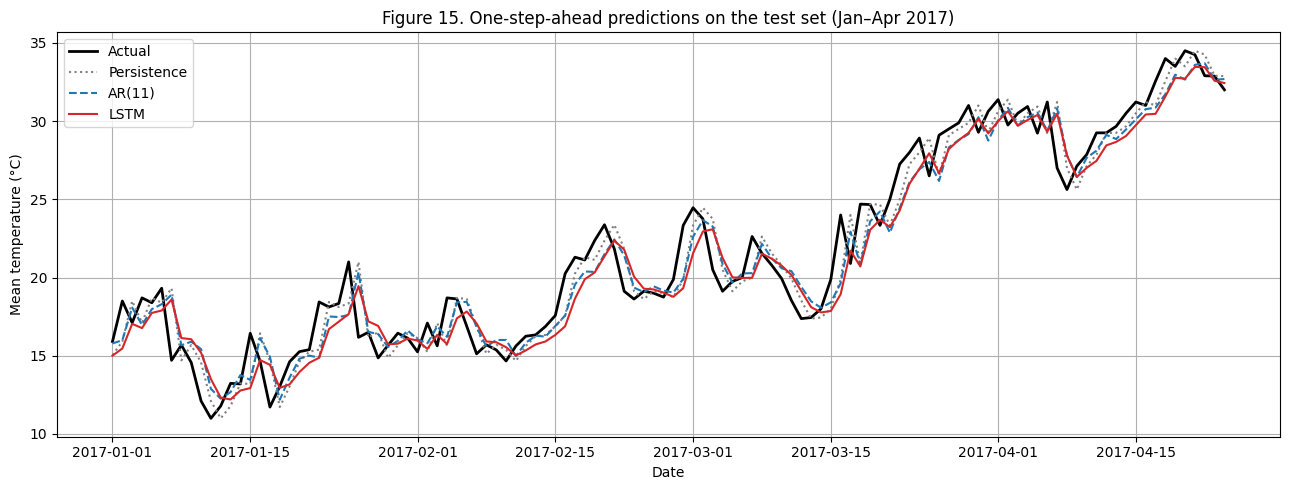

In [47]:
# Full test period
plt.figure(figsize=(13, 5))
plt.plot(y_test.index, y_test, color='black', linewidth=2, label='Actual')
plt.plot(y_test.index, pers_test, color='grey', linestyle=':', label='Persistence')
plt.plot(y_test.index, ar_test_pred, color='tab:blue', linestyle='--', label=f'AR({BEST_P_ORIG})')
plt.plot(y_test.index, lstm_test_pred, color='tab:red', label='LSTM')
plt.title('Figure 15. One-step-ahead predictions on the test set (Jan–Apr 2017)')
plt.xlabel('Date')
plt.ylabel('Mean temperature (°C)')
plt.legend()
plt.tight_layout()
plt.show()

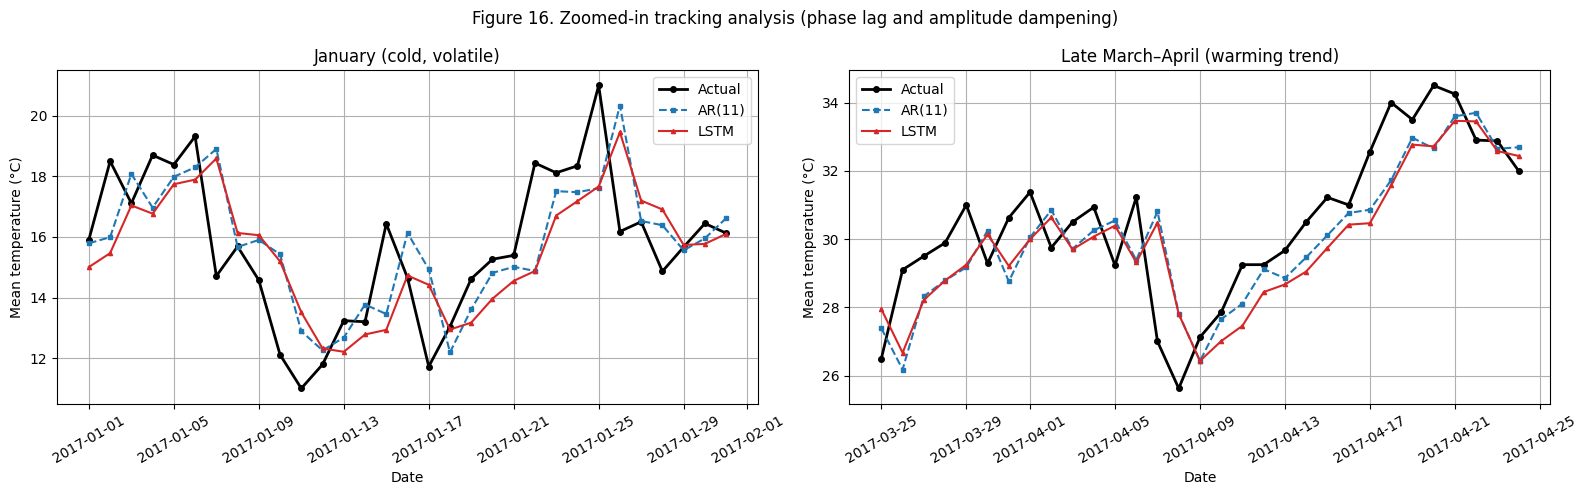

In [49]:
# Zoomed windows
windows = [('2017-01-01', '2017-01-31', 'January (cold, volatile)'),
           ('2017-03-25', '2017-04-24', 'Late March–April (warming trend)')]

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=False)
for ax, (start, end, label) in zip(axes, windows):
    sl = slice(start, end)
    ax.plot(y_test.loc[sl].index, y_test.loc[sl], 'o-', color='black', linewidth=2, markersize=4, label='Actual')
    ax.plot(ar_test_pred.loc[sl].index, ar_test_pred.loc[sl], 's--', color='tab:blue', markersize=3,
            label=f'AR({BEST_P_ORIG})')
    ax.plot(lstm_test_pred.loc[sl].index, lstm_test_pred.loc[sl], '^-', color='tab:red', markersize=3, label='LSTM')
    ax.set_title(label)
    ax.set_xlabel('Date')
    ax.set_ylabel('Mean temperature (°C)')
    ax.tick_params(axis='x', rotation=30)
    ax.legend()
plt.suptitle('Figure 16. Zoomed-in tracking analysis (phase lag and amplitude dampening)')
plt.tight_layout()
plt.show()

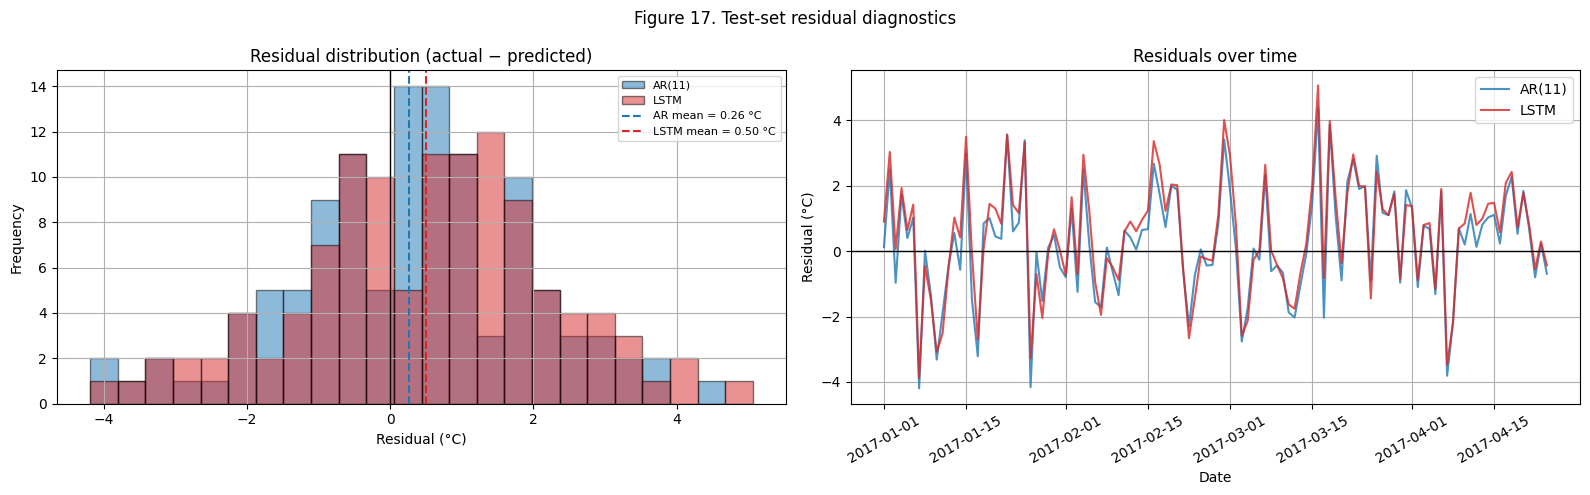

Correlation between AR and LSTM residuals: 0.971


In [50]:
# Residual diagnostics
ar_res   = y_test - ar_test_pred
lstm_res = y_test - lstm_test_pred

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

bins = np.linspace(min(ar_res.min(), lstm_res.min()), max(ar_res.max(), lstm_res.max()), 25)
axes[0].hist(ar_res,   bins=bins, alpha=0.5, color='tab:blue', edgecolor='black', label=f'AR({BEST_P_ORIG})')
axes[0].hist(lstm_res, bins=bins, alpha=0.5, color='tab:red',  edgecolor='black', label='LSTM')
axes[0].axvline(ar_res.mean(),   color='tab:blue', linestyle='--', label=f'AR mean = {ar_res.mean():.2f} °C')
axes[0].axvline(lstm_res.mean(), color='tab:red',  linestyle='--', label=f'LSTM mean = {lstm_res.mean():.2f} °C')
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set_title('Residual distribution (actual − predicted)')
axes[0].set_xlabel('Residual (°C)')
axes[0].set_ylabel('Frequency')
axes[0].legend(fontsize=8)

axes[1].plot(ar_res.index,   ar_res,   color='tab:blue', alpha=0.8, label=f'AR({BEST_P_ORIG})')
axes[1].plot(lstm_res.index, lstm_res, color='tab:red',  alpha=0.8, label='LSTM')
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_title('Residuals over time')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Residual (°C)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend()

plt.suptitle('Figure 17. Test-set residual diagnostics')
plt.tight_layout()
plt.show()

print(f"Correlation between AR and LSTM residuals: {np.corrcoef(ar_res, lstm_res)[0, 1]:.3f}")

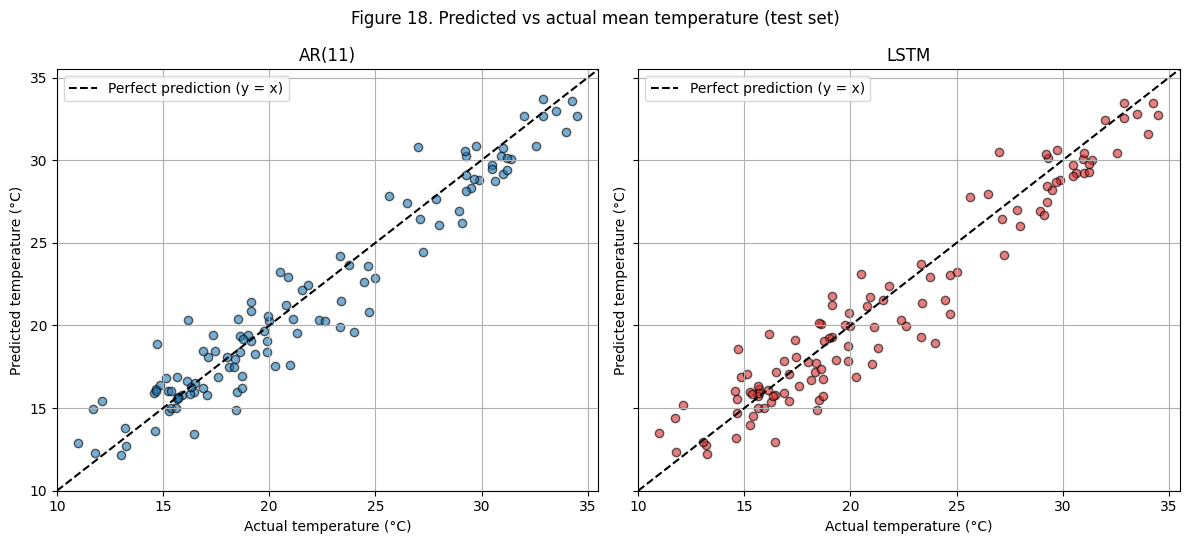

In [51]:
# Predicted vs actual
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
lims = [y_test.min() - 1, y_test.max() + 1]
for ax, pred, name, color in [(axes[0], ar_test_pred, f'AR({BEST_P_ORIG})', 'tab:blue'),
                              (axes[1], lstm_test_pred, 'LSTM', 'tab:red')]:
    ax.scatter(y_test, pred, alpha=0.6, color=color, edgecolor='black')
    ax.plot(lims, lims, 'k--', label='Perfect prediction (y = x)')
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_title(name)
    ax.set_xlabel('Actual temperature (°C)')
    ax.set_ylabel('Predicted temperature (°C)')
    ax.legend()
plt.suptitle('Figure 18. Predicted vs actual mean temperature (test set)')
plt.tight_layout()
plt.show()

In [52]:
# Post-hoc sensitivity check
def run_lstm_fixed_epochs(cfg, history, target, seed, epochs):
    """Train for a fixed number of epochs on ALL of `history` (no early-stopping hold-out)."""
    tf.keras.utils.set_random_seed(seed)
    X_tr, y_tr_s, X_ev, _, scaler = prepare_data(history, target, cfg['seq_len'])
    model = build_lstm(cfg['seq_len'], cfg['units'], cfg['n_layers'], cfg['dropout'], cfg['lr'])
    model.fit(X_tr, y_tr_s, epochs=epochs, batch_size=cfg['batch_size'], verbose=0)
    pred_s = model(X_ev, training=False).numpy()
    return pd.Series(scaler.inverse_transform(pred_s).flatten(), index=target.index)

sens_rows, sens_preds = [], []
for s in SEEDS:
    pred = run_lstm_fixed_epochs(BEST_LSTM_CFG, y_full_train, y_test, s, epochs=300)
    m = evaluate(y_test, pred, 'LSTM (fixed 300 epochs)')
    m['seed'] = s
    sens_rows.append(m); sens_preds.append(pred)

sens_df = pd.DataFrame(sens_rows)
display(sens_df.round(3))
print(f"Fixed-300-epoch LSTM test RMSE: {sens_df['RMSE (°C)'].mean():.3f} ± {sens_df['RMSE (°C)'].std():.3f} °C")
print(f"(Primary early-stopping result: 1.878 ± 0.185 °C | AR(11): 1.700 | Persistence: 1.684)")

tracking_sens = pd.DataFrame([tracking_stats(y_test, p, f'LSTM fixed-300 (seed {s})')
                              for p, s in zip(sens_preds, SEEDS)])
display(tracking_sens.round(3))

,Model,RMSE (°C),MAE (°C),MAPE (%),seed
0,LSTM (fixed 300 epochs),1.670,1.300,6.543,42
1,LSTM (fixed 300 epochs),1.782,1.431,6.957,43
2,LSTM (fixed 300 epochs),1.669,1.304,6.533,44


Fixed-300-epoch LSTM test RMSE: 1.707 ± 0.065 °C
(Primary early-stopping result: 1.878 ± 0.185 °C | AR(11): 1.700 | Persistence: 1.684)


,Model,"Corr(ŷₜ, yₜ) [k=0]","Corr(ŷₜ, yₜ₋₁) [k=1]",Best-matching lag k (days),Std of daily changes: pred / actual,"Mean bias, actual − pred (°C)"
0,LSTM fixed-300 (seed 42),0.965,0.997,1,0.747,0.137
1,LSTM fixed-300 (seed 43),0.965,0.997,1,0.751,0.648
2,LSTM fixed-300 (seed 44),0.965,0.997,1,0.755,0.212


### 7.1 Test-set results

**Table 12. Final test-set performance (114 days, one-step-ahead)**

| Model | RMSE (°C) | MAE (°C) | MAPE (%) | RMSE vs persistence | Val RMSE (for reference) |
|---|---|---|---|---|---|
| Persistence (ŷₜ = yₜ₋₁) | **1.684** | **1.314** | **6.645** | n/a | 1.662 |
| AR(11) | 1.700 | 1.339 | 6.648 | +0.9% | 1.575 |
| AR(10), differenced | 1.708 | 1.347 | 6.686 | +1.4% | 1.574 |
| LSTM (3 seeds) | 1.878 ± 0.185 | 1.537 ± 0.189 | 7.731 ± 0.988 | +11.5% | 1.566 ± 0.004 |

**Table 13. Tracking diagnostics: phase lag and amplitude dampening**

| Model | Corr(ŷₜ, yₜ) | Corr(ŷₜ, yₜ₋₁) | Best-matching lag | Std of daily changes (pred / actual) | Mean bias, actual − pred (°C) |
|---|---|---|---|---|---|
| Persistence | 0.965 | 1.000 | 1 day | 0.999 | +0.149 |
| AR(11) | 0.964 | 0.997 | 1 day | 0.776 | +0.259 |
| AR(10), differenced | 0.964 | 0.997 | 1 day | 0.780 | +0.319 |
| LSTM (seed 42) | 0.962 | 0.994 | 1 day | 0.606 | +0.497 |

**Table 14. Computational cost (final models)**

| Model | Parameters | Training time (s) | Inference time, 114 days (s) | Run-to-run variability |
|---|---|---|---|---|
| AR(11) | 12 | 0.0125 | 0.0025 | None (deterministic) |
| LSTM | 1,169 | 42.4 (mean) | 0.036 | Test RMSE std 0.185 °C |

**Key findings**

1. **No model outperformed persistence on the test set.** AR(11) was within 1% of
   persistence, which is not a meaningful difference on 114 test days. The LSTM was 11.5%
   worse on average. The ranking seen during validation (LSTM ≈ AR < persistence) did not
   carry over to the 2017 winter–spring test period.
2. **The LSTM's degradation is linked to the final retraining procedure** (confirmed in
   Section 7.2). During tuning, the selected configuration trained for the full 300 epochs,
   with very low variability between seeds (std 0.004 °C). When it was retrained on the full
   training file, the early-stopping hold-out became the last 10% of 2016 (the autumn
   cooling period), and training stopped after only 86–139 epochs. The final models were
   therefore under-trained relative to the tuned ones, and variability between seeds grew
   about 45-fold (std 0.185 °C). The seed that stopped earliest (86 epochs) performed worst
   (RMSE 2.090 °C).
3. **All models exhibit a one-day phase lag.** Every model's predictions correlate more
   strongly with the *previous* day's actual temperature (0.994–0.997) than with the
   current day's (0.962–0.965) (Table 13). AR and the LSTM therefore behave very similarly
   to persistence. This is visible in Figure 16, where predicted peaks appear one day
   after the actual peaks.
4. **Amplitude dampening is strongest for the LSTM.** Its day-to-day changes are only 61%
   as large as the actual changes (78% for AR). Peaks are under-predicted (Figure 16), and
   at high temperatures the LSTM's predictions fall below the y = x line (Figure 18).
5. **Phase lag combined with the warming trend produces a positive bias.** The test period
   warms by about 17 °C over 114 days (≈ 0.15 °C/day), and the persistence model's mean
   bias (+0.149 °C) equals exactly this average daily rise. Any model that lags behind a
   rising series under-predicts. Because the LSTM also dampens changes, it under-predicts
   the most (+0.50 °C vs +0.26 °C for AR; Figure 17).
6. **Errors are dominated by unpredictable weather events.** The AR and LSTM residuals are
   almost perfectly correlated (r = 0.971; Figure 17, right): both models fail on the same
   days, mainly sudden temperature changes such as 6–7 January (19.3 → 14.7 °C) and
   7–8 April (31.2 → 25.6 °C). These events cannot be anticipated from past temperature
   alone, so the error floor is set by the information in the data rather than by the
   choice of model.
7. **Computational cost:** Both models predict in milliseconds, but the LSTM took about
   3,400 times longer to train, has about 100 times more parameters, and produced
   seed-dependent results, whereas AR is deterministic.

### 7.2 Post-hoc sensitivity analysis: retraining duration
*This analysis was designed after viewing the test results. It is reported only to explain
the LSTM's degradation and does not replace the pre-specified result in Table 12.*

To test whether early stopping caused the LSTM's degradation, the selected LSTM was
retrained on the full training file for a fixed 300 epochs (matching the tuning phase) with
no early-stopping hold-out.

**Table 15. LSTM test performance: early stopping vs fixed 300 epochs**

| Training procedure | Test RMSE (°C) | Std between seeds | Per-seed RMSE (°C) | Std of daily changes (pred / actual) | Mean bias (°C) |
|---|---|---|---|---|---|
| Early stopping (pre-specified, Table 12) | 1.878 | 0.185 | 1.798 / 1.747 / 2.090 | 0.606 (seed 42) | +0.497 (seed 42) |
| Fixed 300 epochs (post-hoc) | **1.707** | **0.065** | 1.670 / 1.782 / 1.669 | 0.747–0.755 | +0.137 to +0.648 |
| *Reference: AR(11)* | *1.700* | *n/a* | n/a | *0.776* | *+0.259* |
| *Reference: Persistence* | *1.684* | *n/a* | n/a | *0.999* | *+0.149* |

**Interpretation**

- **The retraining procedure was the main cause of the LSTM's poor test performance.** With
  the same training length as in tuning, mean test RMSE fell from 1.878 to 1.707 °C,
  essentially equal to AR(11) (1.700 °C), and the spread between seeds dropped by about
  two-thirds (std 0.185 → 0.065 °C).
- **Dampening was reduced.** The ratio of predicted to actual daily changes rose from 0.61
  to about 0.75, close to AR's 0.78. The under-trained early-stopped models were
  over-smoothing; with full training, the LSTM tracks daily fluctuations about as well as
  AR.
- **Two of three seeds slightly beat persistence** (1.669–1.670 °C vs 1.684 °C), but the
  margin (≈ 0.9%) is not meaningful on 114 test days. Seed 43 was worse (1.782 °C)
  because of a systematic positive offset (mean bias +0.648 °C), which shows that some
  run-to-run instability remains even with consistent training.
- **The one-day phase lag persists** (best-matching lag = 1 day for all seeds), confirming
  that phase lag is a property of the data and the one-step-ahead task, not of the
  training procedure.
- **Methodological lesson:** When a model is refitted on a larger training set after
  tuning, the training procedure must be kept consistent with the one used during tuning.
  Using a fixed epoch count (the one found during tuning) is safer than relying on a new
  early-stopping hold-out, whose characteristics (here, an autumn cooling period) may
  differ from the tuning conditions. For deep learning models, **the retraining protocol
  can matter as much as the architecture.**
- **Overall conclusion of Section 7:** When trained consistently, the LSTM performs on par
  with AR(11), and neither model meaningfully improves on persistence for one-day-ahead
  prediction of Delhi's daily mean temperature. AR achieves this with 12 parameters, a
  training time of about 0.01 s and fully deterministic results.

## 8. Discussion

### 8.1 Overall comparison
On the held-out test set, neither model meaningfully improved on the naive persistence
forecast (Table 12). AR(11) was within 1% of persistence, and the LSTM, once trained
consistently with the tuning protocol, performed on par with AR(11) (1.707 vs 1.700 °C;
Table 15). The central finding of this study is therefore not that one model "wins," but
that **for one-day-ahead prediction of Delhi's daily mean temperature, almost all of the
predictable information is already contained in yesterday's value**. Both a 12-parameter
linear model and a 1,169-parameter recurrent network converge on essentially the same
forecast. The sections below explain why.

### 8.2 Linear (AR) vs non-linear (LSTM) dynamics
The AR model is a fixed linear combination of past values, while the LSTM can learn
non-linear relationships and, through its gated memory cell, longer-term dependencies.
In theory the LSTM is the more expressive model. In practice its extra capacity brought no
benefit, for four related reasons:

1. **The dominant structure is linear persistence.** The lag-1 partial autocorrelation is
   0.972 (Section 3), and the fitted AR coefficients sum to 0.987 (Table 7), close to a
   random walk. A linear model captures this almost completely.
2. **No linear structure remained for the LSTM to improve on, and little evidence of
   non-linear structure was found.** The AR(11) residuals passed the Ljung-Box test
   (Table 8), and the AR and LSTM test residuals are almost perfectly correlated
   (r = 0.971; Figure 17). If the LSTM had found genuine non-linear patterns, its errors
   would differ systematically from those of AR. Instead, both models fail on the same
   days.
3. **The dependencies are short-term, so the LSTM's main advantage is not used.** LSTMs
   were designed to overcome the vanishing-gradient problem and retain information over
   long sequences. Here, the best window length was only 7 days (Experiment B), which
   agrees with the PACF (significant lags within about 4–11 days) and the AR order
   (p = 11). Over such short spans, even a simple linear model has no difficulty
   "remembering."
4. **The problem is simple and the dataset is small.** Increasing hidden units from 16 to
   64 changed validation RMSE by less than 0.003 °C despite a 14-fold increase in
   parameters (Experiment C), and adding a second layer made performance worse
   (Experiment D). With only about 1,170 training sequences from a single univariate
   series, the extra capacity cannot be used productively and instead increases the risk
   of overfitting and run-to-run variability.

Both models also see the **same information**: past temperature only. The largest errors
come from abrupt weather changes (e.g. 6–7 January and 7–8 April 2017) that are driven by
factors not present in the input, such as rainfall, cloud cover or the arrival of cold air.
Choosing a non-linear model cannot recover information that is absent from the inputs.

### 8.3 Phase lag
All models exhibit a **one-day phase lag**: their predictions correlate more strongly
with the *previous* day's temperature (0.994–0.997) than with the actual temperature on
the day being predicted (0.962–0.965) (Table 13). In Figure 16, predicted peaks and troughs
consistently appear one day after the real ones.

This is not a coding error but a direct consequence of the task and the data. For a highly
persistent series, the forecast that minimises squared error, given only past values, is
very close to the most recent observation. A sudden change on day t cannot be seen in data
up to day t − 1, so it is only "learned" one step later. Both models therefore behave as a
slightly refined version of persistence.

This has two important implications:
- **Low RMSE does not mean useful foresight.** An RMSE of about 1.7 °C may look good in
  isolation, but persistence achieves the same with no model at all. Without a persistence
  baseline, the AR and LSTM results would have appeared more impressive than they are.
- **The lag interacts with trends to create bias.** During the 2017 warming period
  (≈ +0.15 °C per day), any lagging forecast systematically under-predicts. The persistence
  model's mean bias (+0.149 °C) equals the average daily warming exactly, and models that
  lag *and* smooth (Section 8.4) show larger bias (Table 13, Figure 17).

Reducing phase lag requires information about *upcoming* changes, for example exogenous
predictors (humidity, pressure tendency, wind), numerical weather forecasts, or
seasonal/calendar features that tell the model which direction temperature is moving at
that time of year.

### 8.4 Amplitude dampening
Both models produce smoother series than reality: AR's day-to-day changes are 78% as large
as the actual changes, and the early-stopped LSTM's only 61% (Table 13). Peaks are
under-predicted and troughs over-predicted (Figures 16 and 18). Three mechanisms
contribute:

1. **Squared-error loss favours cautious predictions.** When a sharp change is
   unpredictable, the prediction that minimises expected squared error is the conditional
   mean, which lies between the possible outcomes. Both models are trained with this loss,
   so they learn to "hedge" towards average values.
2. **Mean reversion in AR.** Because the AR coefficients sum to slightly less than 1
   (0.987), each forecast is pulled slightly towards the long-run mean (≈ 26.1 °C),
   which dampens extremes.
3. **Under-training increases smoothing in the LSTM.** The early-stopped LSTMs (86–139
   epochs) had the strongest dampening (0.61). With full 300-epoch training, the ratio rose
   to about 0.75 (Table 15), close to AR. An under-fitted network outputs a smoother,
   more average-like function of its inputs.

In engineering terms, dampening matters because the **extremes are often what a system
must be designed for**. A building cooling-load model, a heat-warning system or an
electricity demand forecast built on these predictions would systematically underestimate
the hottest days. Where extremes matter, the loss function, evaluation metrics (e.g. errors
on peak days) and inputs should be chosen specifically to capture them.

### 8.5 Non-stationarity, seasonality and the validation–test gap
The ADF test showed that the series is non-stationary because of its strong yearly cycle
and gradual upward trend (Table 2, Figure 3). Neither model captures this cycle directly:
AR(11) and a 7-day LSTM window see at most 11 days of history, while the seasonal pattern
spans 365 days. Explicitly differencing the series made no difference (Table 12), because
with Σφ ≈ 0.987 the AR model already behaves almost like a model of daily changes.

The validation and test periods also differ in character. Validation (March–December 2016)
covered the hot season and the autumn cooling phase, whereas the test period
(January–April 2017) is a cold, volatile period followed by rapid warming. Both models
improved on persistence by about 5% on validation but not on test. This shows that small
gains measured on one season do not necessarily transfer to another, which is a form of
**distribution shift**. A more reliable estimate would require evaluation across all
seasons, for example with rolling-origin (walk-forward) validation.

### 8.6 Robustness and reproducibility
The AR model is deterministic: refitting it always gives identical coefficients and
predictions. The LSTM's results depend on the random seed and the training procedure. The
selected configuration varied by only ±0.004 °C between seeds during tuning, but by
±0.185 °C when retrained with a new early-stopping hold-out, and still by ±0.065 °C with
fixed-epoch training. One seed under-predicted systematically (bias +0.648 °C;
Section 7.2).

The sensitivity analysis also showed that the **retraining protocol** changed the LSTM's
test RMSE by about 10% (1.878 → 1.707 °C). This is as large as any architectural choice
made during tuning. For deep learning models, reproducibility therefore requires fixing
not just the seeds and architecture, but the complete training procedure, including the
stopping criterion used when refitting.

### 8.7 Deployment constraints

**Table 16. Deployment comparison**

| Factor | AR(11) | LSTM |
|---|---|---|
| Accuracy (test RMSE, consistent training) | 1.700 °C | 1.707 ± 0.065 °C |
| Parameters | 12 | 1,169 |
| Training time | ≈ 0.01 s | ≈ 42 s per run (≈ 3,400× slower) |
| Hyperparameter tuning | Order sweep in ≈ 1 s | About an hour of compute in total ([N] training runs) |
| Inference time (114 days) | 0.003 s | 0.036 s |
| Hardware / software | Runs anywhere; a few multiplications per prediction | Needs a deep-learning framework; GPU helpful for training |
| Determinism | Fully deterministic | Seed-dependent; sensitive to retraining protocol |
| Interpretability | Each coefficient has a clear meaning (e.g. φ₁ = 0.78) | Black box |
| Retraining / maintenance | Trivial to refit as new data arrives | Requires re-tuning or careful protocol, plus validation of each retrained model |

For a practical engineering application, such as a temperature forecast embedded in a
building energy-management controller or a low-power environmental sensor, **AR(11) is the
clear choice for this task**. It matches the LSTM's accuracy, can be implemented in a
few lines of code on a microcontroller, retrains instantly as new data arrives, and its
behaviour can be explained to engineers and auditors. In fact, the persistence model, which
requires no training at all, would be an acceptable choice for one-day-ahead forecasting.

An LSTM would become worth its cost under different conditions: when **multiple input
variables** with non-linear interactions are available (e.g. humidity, pressure, wind,
solar radiation), when predicting **several days ahead**, where error accumulation and
non-linear dynamics matter more, when **much larger datasets** are available (e.g. hourly
data or many stations), or when the system has genuinely **non-linear regimes** (e.g.
monsoon onset).

### 8.8 Limitations
- **Small test set:** 114 days from a single season. Differences of 1–2% in RMSE are within
  the range expected from random variation, and no formal significance test (e.g.
  Diebold–Mariano) was performed.
- **Univariate inputs:** Only past temperature was used. Humidity, wind and pressure were
  available but not used as predictors.
- **One-step-ahead horizon only:** Multi-step forecasting, where the models may differ
  more, was not evaluated.
- **Greedy tuning:** Hyperparameters were tuned one at a time, so interactions (e.g.
  between learning rate and window length) were not fully explored.
- **Training limits:** The best LSTM configurations reached the 300-epoch cap during
  tuning, so slightly longer training might give marginal improvements.
- **Single split and single location:** Results are based on one chronological split of
  one city's data. Rolling-origin evaluation across multiple years and seasons would give
  more robust conclusions.

## 9. Conclusion

This study compared an autoregressive (AR) model and a Long Short-Term Memory (LSTM) network
for one-day-ahead prediction of daily mean temperature in Delhi, using a chronological
train/validation/test protocol, a persistence baseline, and controlled hyperparameter
tuning. Exploratory analysis showed that the series is non-stationary, strongly seasonal
and highly persistent (lag-1 partial autocorrelation 0.972), with short-term dependence
concentrated within about 4–11 days. These findings guided the selection of AR(11) and an
LSTM with a 7-day input window and 16 hidden units.

On the held-out 2017 test set, AR(11) achieved an RMSE of 1.700 °C. The LSTM achieved
1.878 °C with the pre-specified retraining procedure and 1.707 °C when retrained
consistently with the tuning protocol. Neither model meaningfully outperformed the naive
persistence forecast (1.684 °C). All models showed a one-day phase lag, and both AR and the
LSTM dampened day-to-day variability, with the LSTM dampening most when under-trained.
The near-identical errors of the two models (residual correlation 0.971) show that
prediction accuracy is limited by the information available in past temperature, not by
model complexity.

Given equal accuracy, AR(11) is preferred for deployment: it has 100 times fewer
parameters, trains about 3,400 times faster, is fully deterministic and is directly
interpretable. The LSTM's non-linear modelling and long-term memory offer no advantage for
this short-horizon, linearly dominated problem, and its results depend on the random seed
and on the retraining protocol.

**Future work**
- Add exogenous predictors (humidity, wind speed, pressure tendency) and calendar or
  seasonal features (e.g. day-of-year encoded with sine/cosine) to provide information
  about upcoming changes.
- Evaluate seasonal models such as SARIMA, and a GRU as a lighter recurrent alternative.
- Compare models on multi-step horizons (e.g. 3–7 days ahead), where differences between
  linear and non-linear models are likely to be larger.
- Use rolling-origin evaluation across several years, with statistical significance tests,
  to obtain more robust conclusions.